# Global Earthquake Forecasting with Deep Learning, ETAS Features & Residual Gradient Boosting (v2)
### An upgraded, rigorous benchmark against statistical baselines (USGS catalog, 2000–2025)

**How to use:** open in Google Colab → *Runtime → Run all*. Data is downloaded automatically from the USGS API (internet required, no files to upload). A GPU is optional (it speeds up the Dual-Branch LSTM and XGBoost).
For a quick first pass, set `RUN_LSTM = False`, `RUN_SENSITIVITY = False`, and `RUN_ROLLING = False` in the config cell.

---

## Key Upgrades in v2 (Driven by v1 Error & Feature-Gain Diagnostics)
In v1, **85.2% of LightGBM's split gain** went into re-learning long-term climatology (`cum_rate` and `cum_cnt_rate`), while fixed 3/6/12-month windows blurred recent aftershock bursts. Version 2 addresses these bottlenecks directly:
1. **ETAS / Omori-Law Time-Decay Features:** Exponential and power-law decayed event counts & seismic energy capture aftershock productivity and temporal decay far better than flat windows.
2. **Short-Term Anomaly & Spatial Ring Features:** Ratios of recent activity to each cell's long-term baseline (`ratio_3_36`, `ratio_12_cum`), 2-ring distance-weighted regional activity, neighbor energy, and $\cos(	ext{lat})$ area weighting.
3. **Residual / Baseline-Offset LightGBM (`init_score`):** Passes smoothed climatology log-odds as a base margin so boosting trees focus 100% of their capacity on spatiotemporal deviations rather than re-learning static rates.
4. **Poisson Count-to-Probability LightGBM:** Trains on monthly event counts (`objective="poisson"`) to preserve information between 1 vs. 50 quakes/month, converting expected count $\hat{\lambda}$ to $P(N \ge 1) = 1 - e^{-\hat{\lambda}}$.
5. **XGBoost + Dual-Branch LSTM + Meta-Ensemble:** Combines diverse model families (Residual LightGBM, Poisson LightGBM, XGBoost, and a Dual-Branch Sequence+Static LSTM) using validation-optimized log-loss blending and isotonic calibration.
6. **Dual Threshold Reporting:** Reports both the **F1-optimal threshold** (for balanced event detection) and the **Accuracy-optimal threshold** (on validation) for complete transparency.

> **Scientific scope.** This is an experimental catalog-based probabilistic forecasting benchmark, **not** deterministic earthquake prediction and **not** an early-warning system.

## 1. Setup and configuration
All settings live in one cell. Change them here, then re-run from the top.

In [1]:
!pip -q install lightgbm xgboost

In [2]:
import os, io, json, time, math, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from numpy.lib.stride_tricks import sliding_window_view
from scipy.optimize import minimize
from scipy.special import logit, expit

from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             log_loss, precision_recall_curve, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

# ------------------------------- CONFIGURATION -------------------------------
START_YEAR, END_YEAR = 2000, 2025      # catalog period downloaded from USGS
MIN_MAG        = 4.5                   # catalog minimum magnitude (USGS is ~complete globally above this)
TARGET_MAG     = 4.5                   # main task: >=1 event of M >= TARGET_MAG in the next month
GRID_DEG       = 5.0                   # grid resolution in degrees
LOOKBACK       = 12                    # months of history used by the LSTM / minimum history for features

TRAIN_END_YEAR = 2017                  # train: target months up to this year
VAL_END_YEAR   = 2020                  # validation: up to this year; test = every later year
ROLL_START_YEAR = 2016                 # rolling-origin evaluation starts here (also defines active-cell set)

RUN_LSTM        = True                 # dual-branch deep sequence model
N_SEEDS         = 3                    # LSTM seeds (mean +- std + ensemble)
LSTM_EPOCHS     = 35
RUN_ROLLING     = True                 # rolling-origin validation
RUN_ABLATION    = True
RUN_SENSITIVITY = True                 # grid-size and target-magnitude sensitivity
SENS_GRIDS      = [10.0, 5.0, 3.0]
SENS_TARGETS    = [4.5, 5.0, 5.5, 6.0]
N_BOOT          = 200                  # bootstrap resamples (by month)
RF_TREES        = 200
LGB_MAX_TREES   = 1200
XGB_MAX_TREES   = 1000
RUN_DEMO        = False                # optional Gradio demo at the end
USE_UPLOAD_FALLBACK = True             # if download fails, allow uploading yearly USGS CSVs
SEED = 42
# ------------------------------------------------------------------------------

np.random.seed(SEED)
OUT_DIR = Path("/content/outputs_v2"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLES = {}

def show(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Config v2 OK | catalog", START_YEAR, "-", END_YEAR, "| M >=", MIN_MAG, "| grid", GRID_DEG, "deg")

Config v2 OK | catalog 2000 - 2025 | M >= 4.5 | grid 5.0 deg


## 2. Download the USGS catalog automatically
Queries the official **USGS FDSN Event API** in half-year windows, splitting any window that exceeds 20,000 events, with retries and local caching. Only `eventtype=earthquake` is requested.

In [3]:
BASE = "https://earthquake.usgs.gov/fdsnws/event/1/"
CACHE = Path("/content/usgs_cache"); CACHE.mkdir(parents=True, exist_ok=True)
USGS_LIMIT = 20000

def _get(endpoint, params, tries=4):
    last = None
    for k in range(tries):
        try:
            r = requests.get(BASE + endpoint, params=params, timeout=180)
            if r.status_code == 200:
                return r
            last = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code == 400:
                break
        except requests.RequestException as e:
            last = repr(e)
        time.sleep(3 * (k + 1))
    raise RuntimeError(f"USGS request failed ({endpoint}): {last}")

def fetch_chunk(start, end):
    '''Download every event in [start, end]; split the window if it exceeds the API limit.'''
    path = CACHE / f"usgs_m{MIN_MAG}_{start}_{end}.csv"
    if path.exists() and path.stat().st_size > 0:
        return [pd.read_csv(path, low_memory=False)]
    p = dict(starttime=start, endtime=end, minmagnitude=MIN_MAG,
             eventtype="earthquake", orderby="time-asc")
    r = _get("count", {**p, "format": "geojson"})
    try:
        n = int(r.json()["count"])
    except Exception:
        n = int(r.text.strip())
    if n == 0:
        return []
    if n > USGS_LIMIT:
        s, e = pd.Timestamp(start), pd.Timestamp(end)
        mid = (s + (e - s) / 2).strftime("%Y-%m-%d")
        if mid in (start, end):
            raise RuntimeError(f"Cannot split window {start} -> {end} any further")
        return fetch_chunk(start, mid) + fetch_chunk(mid, end)
    r = _get("query", {**p, "format": "csv", "limit": USGS_LIMIT})
    path.write_bytes(r.content)
    return [pd.read_csv(io.BytesIO(r.content), low_memory=False)]

windows = []
for y in range(START_YEAR, END_YEAR + 1):
    windows += [(f"{y}-01-01", f"{y}-07-01"), (f"{y}-07-01", f"{y+1}-01-01")]

frames = []
try:
    for s, e in windows:
        parts = fetch_chunk(s, e)
        frames += parts
        print(f"{s} -> {e}: {sum(len(x) for x in parts):>6,} events")
except Exception as exc:
    print("\nAutomatic download failed:", exc)
    if not USE_UPLOAD_FALLBACK:
        raise
    from google.colab import files
    print("Please upload the yearly USGS CSV files (M>=4.5, 2000-2025).")
    up = files.upload()
    frames = [pd.read_csv(io.BytesIO(b), low_memory=False) for b in up.values()]

raw = pd.concat(frames, ignore_index=True, sort=False)
print(f"\nRaw rows downloaded: {len(raw):,}")

2000-01-01 -> 2000-07-01:  2,184 events
2000-07-01 -> 2001-01-01:  2,826 events
2001-01-01 -> 2001-07-01:  2,319 events
2001-07-01 -> 2002-01-01:  2,361 events
2002-01-01 -> 2002-07-01:  2,235 events
2002-07-01 -> 2003-01-01:  2,728 events
2003-01-01 -> 2003-07-01:  2,226 events
2003-07-01 -> 2004-01-01:  2,909 events
2004-01-01 -> 2004-07-01:  2,835 events
2004-07-01 -> 2005-01-01:  3,348 events
2005-01-01 -> 2005-07-01:  4,563 events
2005-07-01 -> 2006-01-01:  3,315 events
2006-01-01 -> 2006-07-01:  3,302 events
2006-07-01 -> 2007-01-01:  3,773 events
2007-01-01 -> 2007-07-01:  3,537 events
2007-07-01 -> 2008-01-01:  3,737 events
2008-01-01 -> 2008-07-01:  3,306 events
2008-07-01 -> 2009-01-01:  3,001 events
2009-01-01 -> 2009-07-01:  2,962 events
2009-07-01 -> 2010-01-01:  3,091 events
2010-01-01 -> 2010-07-01:  3,697 events
2010-07-01 -> 2011-01-01:  3,517 events
2011-01-01 -> 2011-07-01:  5,828 events
2011-07-01 -> 2012-01-01:  3,756 events
2012-01-01 -> 2012-07-01:  3,830 events


## 3. Cleaning, validation and data-quality audit
Every filtering step is logged so the pre-processing can be reported transparently.

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip().str.lower()
log = [("Raw rows downloaded", len(df))]

df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
for c in ["latitude", "longitude", "depth", "mag"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["time", "latitude", "longitude", "mag"]);                 log.append(("After dropping missing time/location/magnitude", len(df)))
if "type" in df.columns:
    df = df[df["type"].astype(str).str.lower() == "earthquake"];                 log.append(("After keeping type == 'earthquake'", len(df)))
df = df[df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)];   log.append(("After coordinate range check", len(df)))
df = df[df["mag"].between(MIN_MAG, 10)];                                         log.append((f"After magnitude range check (>= {MIN_MAG})", len(df)))
df = df.drop_duplicates(subset="id" if "id" in df.columns else ["time", "latitude", "longitude", "mag"]); log.append(("After removing duplicates", len(df)))
t0, t1 = pd.Timestamp(f"{START_YEAR}-01-01", tz="UTC"), pd.Timestamp(f"{END_YEAR+1}-01-01", tz="UTC")
df = df[(df["time"] >= t0) & (df["time"] < t1)];                                 log.append(("After restricting to the study period", len(df)))
df["depth"] = df["depth"].clip(lower=0)
df = df.sort_values("time").reset_index(drop=True)

cleaning_log = pd.DataFrame(log, columns=["Step", "Rows"])
TABLES["cleaning_log"] = cleaning_log
display(cleaning_log)
print("Period:", df["time"].min(), "->", df["time"].max())

,Step,Rows
0,Raw rows downloaded,181601
1,After dropping missing time/location/magnitude,181601
2,After keeping type == 'earthquake',181601
3,After coordinate range check,181601
4,After magnitude range check (>= 4.5),181600
5,After removing duplicates,181600
6,After restricting to the study period,181600


Period: 2000-01-01 01:19:26.990000+00:00 -> 2025-12-31 23:04:28.213000+00:00


In [5]:
audit = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean() * 100).round(2), "dtype": df.dtypes.astype(str)})
display(audit[audit["missing"] > 0].sort_values("missing_%", ascending=False).head(12))

MW_TYPES = {"mw", "mww", "mwc", "mwb", "mwr", "mwp"}
mt = df["magtype"].astype(str).str.lower() if "magtype" in df.columns else pd.Series("unknown", index=df.index)
df["mag_family"] = np.select([mt.isin(MW_TYPES), mt.eq("mb"), mt.isin({"ml", "md", "mlr"})],
                             ["Mw family", "mb", "ml/md"], default="other")
share = df["mag_family"].value_counts(normalize=True).mul(100).round(1)
print("Magnitude-type share (%):"); display(share.to_frame("percent"))

,missing,missing_%,dtype
horizontalerror,97440,53.66,float64
magerror,91532,50.40,float64
dmin,90055,49.59,float64
nst,67367,37.10,float64
deptherror,56085,30.88,float64
magnst,28715,15.81,float64
gap,17308,9.53,float64
rms,4877,2.69,float64


Magnitude-type share (%):


,percent
mag_family,
mb,78.4
Mw family,20.5
ml/md,0.8
other,0.3


## 4. Exploratory analysis and catalog completeness

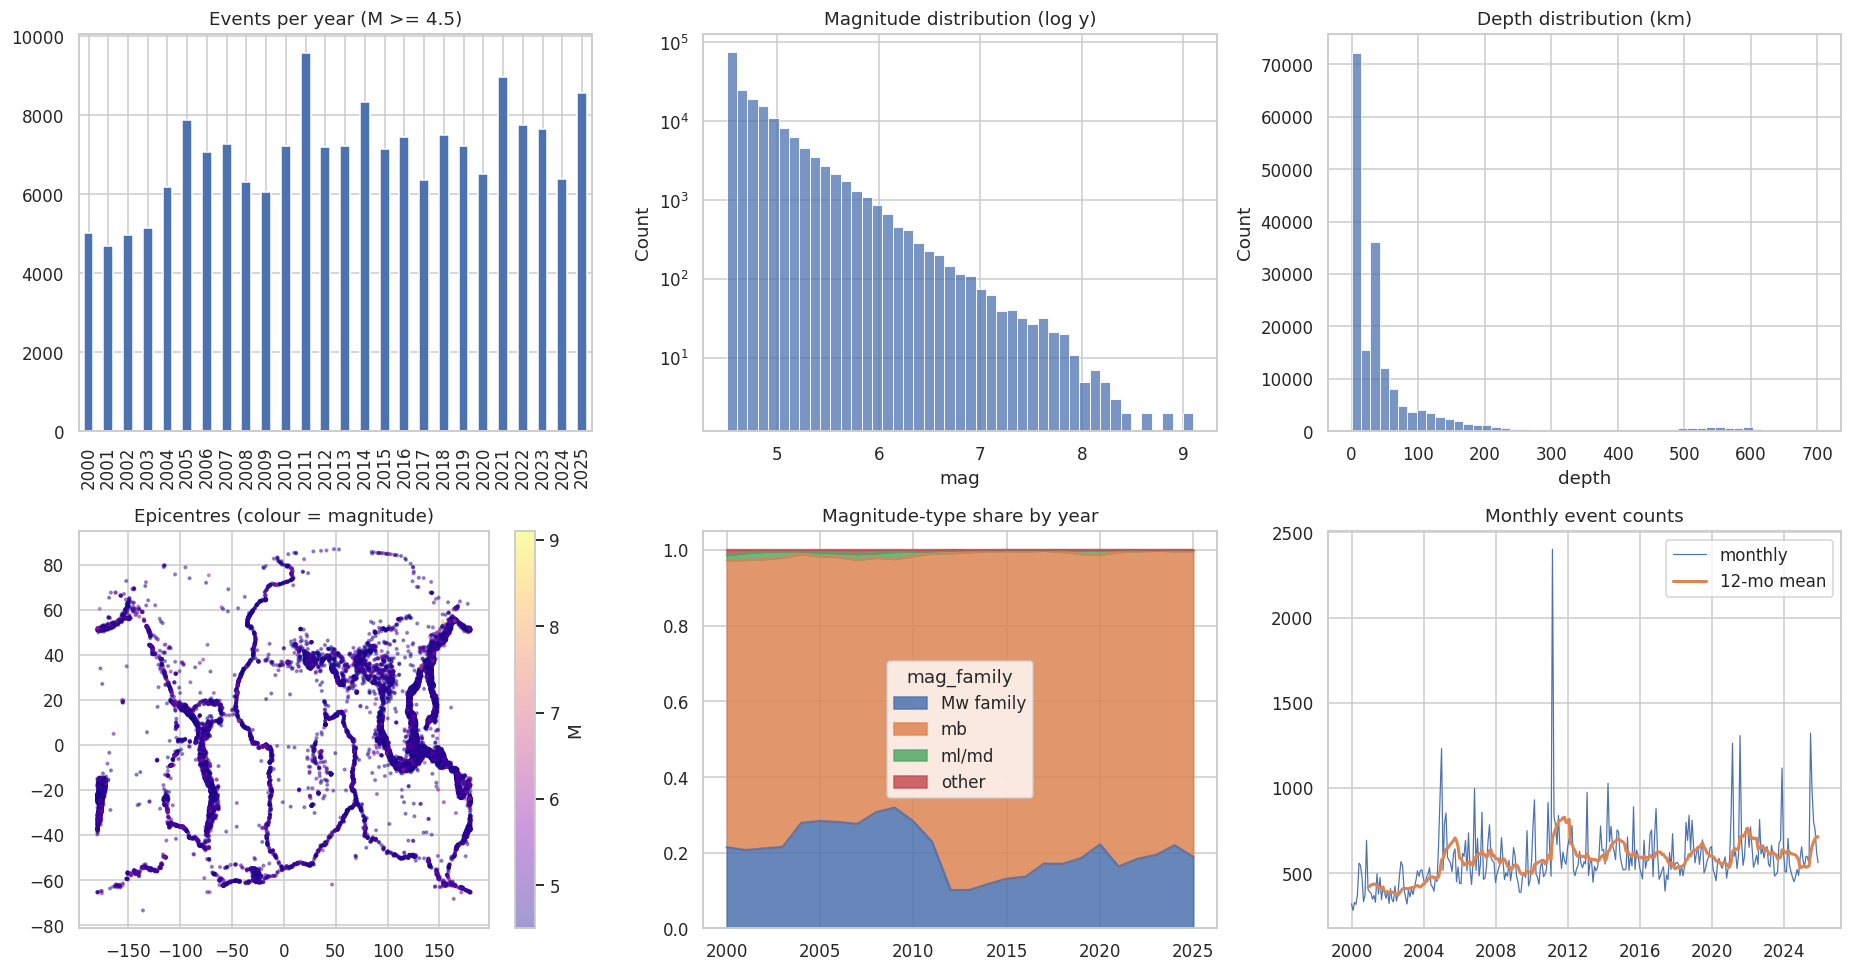

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
yc = df.groupby(df["time"].dt.year).size()
yc.plot(kind="bar", ax=ax[0, 0], color="#4c72b0"); ax[0, 0].set_title("Events per year (M >= %.1f)" % MIN_MAG); ax[0, 0].set_xlabel("")
sns.histplot(df["mag"], bins=45, ax=ax[0, 1]); ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Magnitude distribution (log y)")
sns.histplot(df["depth"], bins=50, ax=ax[0, 2]); ax[0, 2].set_title("Depth distribution (km)")
smp = df.sample(min(len(df), 30000), random_state=SEED)
sc = ax[1, 0].scatter(smp["longitude"], smp["latitude"], c=smp["mag"], s=3, alpha=.4, cmap="plasma")
ax[1, 0].set_title("Epicentres (colour = magnitude)"); plt.colorbar(sc, ax=ax[1, 0], label="M")
fam = pd.crosstab(df["time"].dt.year, df["mag_family"], normalize="index")
fam.plot(kind="area", stacked=True, ax=ax[1, 1], alpha=.85); ax[1, 1].set_title("Magnitude-type share by year"); ax[1, 1].set_xlabel("")
mc = df.set_index("time").resample("MS").size()
ax[1, 2].plot(mc.index, mc.values, lw=.8, label="monthly"); ax[1, 2].plot(mc.index, mc.rolling(12).mean(), lw=2, label="12-mo mean")
ax[1, 2].set_title("Monthly event counts"); ax[1, 2].legend()
show("01_eda_overview")

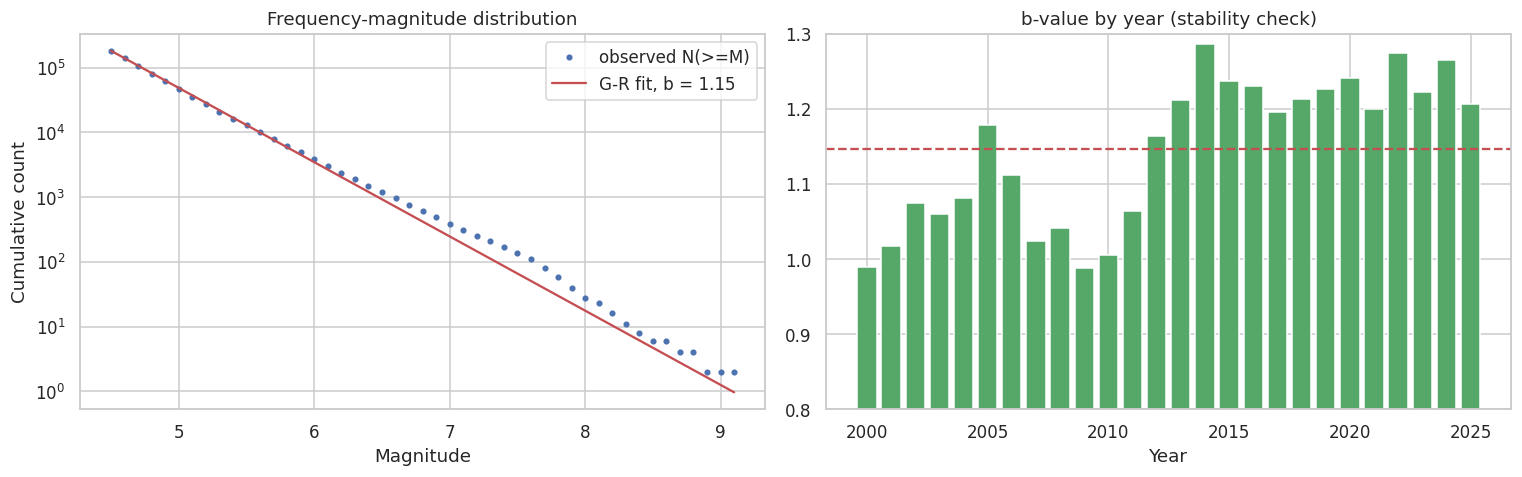

Global b-value = 1.147


In [7]:
mags = df["mag"].values
b_global = np.log10(np.e) / (mags.mean() - (MIN_MAG - 0.05))
levels = np.arange(MIN_MAG, mags.max() + 0.01, 0.1)
N = np.array([(mags >= m - 1e-9).sum() for m in levels])
a_val = np.log10(len(mags)) + b_global * MIN_MAG

by_year = {y: np.log10(np.e) / (g.mag.mean() - (MIN_MAG - 0.05)) for y, g in df.groupby(df["time"].dt.year)}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].semilogy(levels, N, "o", ms=3, label="observed N(>=M)")
ax[0].semilogy(levels, 10 ** (a_val - b_global * levels), "r-", label=f"G-R fit, b = {b_global:.2f}")
ax[0].set_xlabel("Magnitude"); ax[0].set_ylabel("Cumulative count"); ax[0].set_title("Frequency-magnitude distribution"); ax[0].legend()
ax[1].bar(list(by_year.keys()), list(by_year.values()), color="#55a868"); ax[1].axhline(b_global, color="r", ls="--")
ax[1].set_ylim(0.8, 1.3); ax[1].set_title("b-value by year (stability check)"); ax[1].set_xlabel("Year")
show("02_gutenberg_richter")
print(f"Global b-value = {b_global:.3f}")

## 5. Upgraded Problem Formulation & Physics-Informed Feature Engineering

To push beyond the v1 plateau (where 85% of split gain went to static cumulative rates), v2 introduces **three new physics-informed feature groups** while keeping strict zero-leakage causality (features at month $t$ use only months $\le t$):

| Feature group | Features | Rationale |
|---|---|---|
| **Current month** | `cnt`, `max_mag`, `mean_mag`, `mean_depth`, `log_en` | Immediate activity & radiated energy (pruned low-gain `strong`, `shallow_frac`, `log_cnt`) |
| **Rolling history** | `r3`, `r6`, `r12`, `r36`, `ev_frac12`, `ev_frac36`, `strong36`, `max_mag12`, `log_en12` | Multi-scale background & activity rates |
| **ETAS / Omori decay (NEW)** | `etas_cnt_fast`, `etas_cnt_slow`, `etas_omori`, `etas_en_fast`, `etas_en_slow`, `etas_prod` | Exponential & Omori-law ($1/(t+c)^p$) time-decayed counts, energy, and productivity ($10^{lpha(M-M_0)}$) |
| **Anomalies & ratios (NEW)** | `ratio_3_36`, `ratio_12_cum`, `ratio_ev_12_cum`, `ratio_en_1_12`, `trend_3_12` | Detects active swarms/aftershock bursts relative to each cell's own baseline |
| **Recency** | `since_ev`, `since_strong`, `log_since_ev` | Temporal clustering & inter-event waiting time |
| **Spatial neighbours (UPGRADED)** | `neigh1`, `neigh3`, `neigh12`, `neigh_etas`, `neigh_en3`, `neigh_ring2_3` | Immediate 8-cell ring + distance-weighted 2nd ring ($10^\circ$–$15^\circ$) & neighbor energy |
| **Long-term rate / b-value** | `cum_rate`, `cum_cnt_rate`, `cum_en_rate`, `b_val` | Expanding background rate & Gutenberg–Richter $b$-value |
| **Location & area (UPGRADED)** | `lat`, `lon`, `abs_lat`, `cos_lat` | Tectonic setting + $\cos(	ext{lat})$ cell area correction |

In [8]:
def roll_sum(a, w):
    cs = np.cumsum(a, axis=1, dtype=np.float64)
    out = cs.copy()
    out[:, w:] = cs[:, w:] - cs[:, :-w]
    return out.astype(np.float32)

def roll_max(a, w):
    pad = np.pad(a, ((0, 0), (w - 1, 0)), constant_values=0)
    return sliding_window_view(pad, w, axis=1).max(axis=-1)

def exp_decay_sum(a, half_life):
    '''Causal exponentially decayed sum along axis=1 (time).'''
    alpha = math.exp(-math.log(2.0) / half_life)
    C, T = a.shape
    out = np.zeros((C, T), dtype=np.float64)
    out[:, 0] = a[:, 0]
    for t in range(1, T):
        out[:, t] = alpha * out[:, t - 1] + a[:, t]
    return out.astype(np.float32)

def omori_decay_sum(a, max_lag=24, c=0.5, p=1.15):
    '''Causal Omori-Utsu power-law kernel convolution over trailing max_lag months.'''
    lags = np.arange(max_lag, dtype=np.float64)
    w = 1.0 / ((lags + c) ** p)
    w = w / w[0]
    C, T = a.shape
    pad = np.pad(a.astype(np.float64), ((0, 0), (max_lag - 1, 0)), constant_values=0.0)
    win = sliding_window_view(pad, max_lag, axis=1)  # (C, T, max_lag) oldest -> newest
    return np.tensordot(win, w[::-1], axes=([-1], [0])).astype(np.float32)

def months_since(mask, cap):
    t = np.arange(mask.shape[1])[None, :]
    last = np.maximum.accumulate(np.where(mask, t, -10**6), axis=1)
    return np.minimum(t - last, cap).astype(np.float32)

def neighbour_ring_sum(D3, radius=1):
    '''Distance-weighted sum of cells at Chebyshev distance == radius; wraps longitude.'''
    out = np.zeros_like(D3)
    for dlat in range(-radius, radius + 1):
        for dlon in range(-radius, radius + 1):
            if max(abs(dlat), abs(dlon)) != radius:
                continue
            weight = 1.0 / math.hypot(dlat, dlon)
            S = np.roll(D3, dlon, axis=1)
            if dlat > 0:
                S = np.concatenate([np.zeros_like(S[:dlat]), S[:-dlat]], 0)
            elif dlat < 0:
                S = np.concatenate([S[-dlat:], np.zeros_like(S[:-dlat])], 0)
            out += weight * S
    return out

FEATURE_GROUPS = {
    "current month":            ["cnt", "max_mag", "mean_mag", "mean_depth", "log_en"],
    "rolling history":          ["r3", "r6", "r12", "r36", "ev_frac12", "ev_frac36", "strong36", "max_mag12", "log_en12"],
    "ETAS / Omori decay":       ["etas_cnt_fast", "etas_cnt_slow", "etas_omori", "etas_en_fast", "etas_en_slow", "etas_prod"],
    "anomalies & ratios":       ["ratio_3_36", "ratio_12_cum", "ratio_ev_12_cum", "ratio_en_1_12", "trend_3_12"],
    "recency":                  ["since_ev", "since_strong", "log_since_ev"],
    "neighbours":               ["neigh1", "neigh3", "neigh12", "neigh_etas", "neigh_en3", "neigh_ring2_3"],
    "long-term rate / b-value": ["cum_rate", "cum_cnt_rate", "cum_en_rate", "b_val"],
    "location & area":          ["lat", "lon", "abs_lat", "cos_lat"],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
STATIC_COLS = ["cum_rate", "cum_cnt_rate", "cum_en_rate", "b_val", "lat", "lon", "abs_lat", "cos_lat",
               "etas_cnt_fast", "etas_omori", "ratio_3_36", "ratio_12_cum", "neigh_etas"]
print(f"{len(FEATURES)} engineered features across {len(FEATURE_GROUPS)} groups")

42 engineered features across 8 groups


In [9]:
def build_dataset(grid_deg):
    n_lat, n_lon = int(np.ceil(180 / grid_deg)), int(np.ceil(360 / grid_deg))
    NC = n_lat * n_lon
    T = (END_YEAR - START_YEAR + 1) * 12

    lat_bin = np.clip(((df["latitude"].values + 90) // grid_deg).astype(int), 0, n_lat - 1)
    lon_bin = np.clip(((df["longitude"].values + 180) // grid_deg).astype(int), 0, n_lon - 1)
    cell = lat_bin * n_lon + lon_bin
    t_ev = (df["time"].dt.year.values - START_YEAR) * 12 + (df["time"].dt.month.values - 1)
    mag = df["mag"].values.astype(np.float32)
    dep = df["depth"].values.astype(np.float32)

    Z = lambda: np.zeros((NC, T), np.float32)
    cnt, strong, summ, dsum, erel, prod, maxm = Z(), Z(), Z(), Z(), Z(), Z(), Z()
    np.add.at(cnt, (cell, t_ev), np.float32(1))
    np.add.at(strong, (cell, t_ev), (mag >= 5.5).astype(np.float32))
    np.add.at(summ, (cell, t_ev), mag)
    np.add.at(dsum, (cell, t_ev), dep)
    np.add.at(erel, (cell, t_ev), (10 ** (1.5 * (mag - MIN_MAG))).astype(np.float32))
    # ETAS productivity proxy: 10^(alpha * (M - M0)) with alpha ~ 0.8
    np.add.at(prod, (cell, t_ev), (10 ** (0.8 * (mag - MIN_MAG))).astype(np.float32))
    np.maximum.at(maxm, (cell, t_ev), mag)

    # Spatial neighbor rings before filtering to active cells
    cnt_3d = cnt.reshape(n_lat, n_lon, T)
    erel_3d = erel.reshape(n_lat, n_lon, T)
    neigh_r1 = neighbour_ring_sum(cnt_3d, radius=1).reshape(NC, T)
    neigh_r2 = neighbour_ring_sum(cnt_3d, radius=2).reshape(NC, T)
    neigh_en_r1 = neighbour_ring_sum(erel_3d, radius=1).reshape(NC, T)

    # Active cells: >= 1 event strictly before ROLL_START_YEAR (zero leakage)
    cut = (ROLL_START_YEAR - START_YEAR) * 12
    act = cnt[:, :cut].sum(1) > 0
    cell_ids = np.where(act)[0]
    cnt, strong, summ, dsum, erel, prod, maxm, neigh_r1, neigh_r2, neigh_en_r1 = [
        a[act] for a in (cnt, strong, summ, dsum, erel, prod, maxm, neigh_r1, neigh_r2, neigh_en_r1)
    ]
    C = len(cell_ids)
    lat_c = ((cell_ids // n_lon) * grid_deg - 90 + grid_deg / 2).astype(np.float32)
    lon_c = ((cell_ids % n_lon) * grid_deg - 180 + grid_deg / 2).astype(np.float32)
    cos_lat_c = np.cos(np.deg2rad(lat_c)).astype(np.float32)

    ev = cnt > 0
    nan_div = lambda num, den: np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0)
    ind = ev.astype(np.float32)
    tt = np.arange(T, dtype=np.float32)[None, :] + 1.0

    # 60-month Aki b-value
    n60, s60 = roll_sum(cnt, 60), roll_sum(summ, 60)
    b = np.log10(np.e) / (s60 / np.maximum(n60, 1) - (MIN_MAG - 0.05))
    b = np.where(n60 >= 20, np.clip(b, 0.5, 2.0), np.nan)

    r3, r6, r12, r36 = roll_sum(cnt, 3), roll_sum(cnt, 6), roll_sum(cnt, 12), roll_sum(cnt, 36)
    ev_frac12, ev_frac36 = roll_sum(ind, 12) / 12.0, roll_sum(ind, 36) / 36.0
    cum_rate = np.cumsum(ind, axis=1) / tt
    cum_cnt_rate = np.cumsum(cnt, axis=1) / tt
    cum_en_rate = np.log1p(np.cumsum(erel, axis=1) / tt)
    log_en = np.log1p(erel)
    log_en12 = np.log1p(roll_sum(erel, 12))
    mm12 = roll_max(maxm, 12)
    se = months_since(ev, 120)

    # ETAS / Omori decay features
    etas_cnt_fast = np.log1p(exp_decay_sum(cnt, half_life=1.5))
    etas_cnt_slow = np.log1p(exp_decay_sum(cnt, half_life=8.0))
    etas_omori = np.log1p(omori_decay_sum(cnt, max_lag=24, c=0.5, p=1.15))
    etas_en_fast = np.log1p(exp_decay_sum(erel, half_life=1.5))
    etas_en_slow = np.log1p(exp_decay_sum(erel, half_life=8.0))
    etas_prod = np.log1p(omori_decay_sum(prod, max_lag=18, c=0.5, p=1.15))
    neigh_etas = np.log1p(exp_decay_sum(neigh_r1, half_life=2.0))

    FA = {
        "cnt": cnt,
        "max_mag": np.where(ev, maxm, np.nan),
        "mean_mag": nan_div(summ, cnt),
        "mean_depth": nan_div(dsum, cnt),
        "log_en": log_en,
        "r3": r3, "r6": r6, "r12": r12, "r36": r36,
        "ev_frac12": ev_frac12, "ev_frac36": ev_frac36,
        "strong36": roll_sum(strong, 36),
        "max_mag12": np.where(mm12 > 0, mm12, np.nan),
        "log_en12": log_en12,
        "etas_cnt_fast": etas_cnt_fast,
        "etas_cnt_slow": etas_cnt_slow,
        "etas_omori": etas_omori,
        "etas_en_fast": etas_en_fast,
        "etas_en_slow": etas_en_slow,
        "etas_prod": etas_prod,
        "ratio_3_36": (r3 / 3.0) / (r36 / 36.0 + 0.05),
        "ratio_12_cum": (r12 / 12.0) / (cum_cnt_rate + 0.05),
        "ratio_ev_12_cum": ev_frac12 / (cum_rate + 0.02),
        "ratio_en_1_12": log_en / (log_en12 + 0.1),
        "trend_3_12": (r3 / 3.0) - (r12 / 12.0),
        "since_ev": se,
        "since_strong": months_since(strong > 0, 120),
        "log_since_ev": np.log1p(se),
        "neigh1": neigh_r1,
        "neigh3": roll_sum(neigh_r1, 3),
        "neigh12": roll_sum(neigh_r1, 12),
        "neigh_etas": neigh_etas,
        "neigh_en3": np.log1p(roll_sum(neigh_en_r1, 3)),
        "neigh_ring2_3": np.log1p(roll_sum(neigh_r2, 3)),
        "cum_rate": cum_rate,
        "cum_cnt_rate": cum_cnt_rate,
        "cum_en_rate": cum_en_rate,
        "b_val": b,
        "lat": np.repeat(lat_c[:, None], T, 1),
        "lon": np.repeat(lon_c[:, None], T, 1),
        "abs_lat": np.repeat(np.abs(lat_c)[:, None], T, 1),
        "cos_lat": np.repeat(cos_lat_c[:, None], T, 1),
    }
    FA = {k: v.astype(np.float32) for k, v in FA.items()}

    # Richer per-month sequence channels for the Dual-Branch LSTM
    z = lambda a: np.nan_to_num(a, nan=0.0)
    S = np.stack([
        np.log1p(cnt),
        z(FA["max_mag"] - MIN_MAG),
        z(FA["mean_mag"] - MIN_MAG),
        np.log1p(strong),
        z(FA["mean_depth"]) / 100.0,
        FA["log_en"],
        FA["etas_prod"],
        np.log1p(neigh_r1),
        np.log1p(neigh_r2),
        FA["log_since_ev"],
        FA["cum_rate"],
        FA["ratio_3_36"],
    ], axis=-1).astype(np.float32)

    # Samples: (cell, month t) predicting month t+1
    ts = np.arange(LOOKBACK - 1, T - 1)
    ci = np.repeat(np.arange(C), len(ts))
    ti = np.tile(ts, C)
    D = dict(
        grid=grid_deg, n_lat=n_lat, n_lon=n_lon, T=T, C=C,
        cell_ids=cell_ids, lat_c=lat_c, lon_c=lon_c,
        FA=FA, S=S, maxm=maxm, cnt=cnt, ci=ci, ti=ti,
        ymax=maxm[ci, ti + 1],
        ycnt=cnt[ci, ti + 1],
        ty=START_YEAR + (ti + 1) // 12,
        tmonth=ti + 1,
    )
    D["X"] = pd.DataFrame({k: FA[k][ci, ti] for k in FEATURES})
    D["maxm_t"] = maxm[ci, ti]
    return D

D = build_dataset(GRID_DEG)
X = D["X"]
print(f"Grid {GRID_DEG} deg -> {D['C']:,} active cells x {D['T']} months | {len(X):,} samples x {X.shape[1]} features")
display(X.describe().T[["mean", "std", "min", "max"]].round(3).head(12))

Grid 5.0 deg -> 1,036 active cells x 312 months | 310,800 samples x 42 features


,mean,std,min,max
cnt,0.567,5.395,0.0,1890.000
max_mag,5.024,0.509,4.5,9.100
mean_mag,4.819,0.292,4.5,7.500
mean_depth,57.134,93.671,0.0,667.390
log_en,0.375,1.076,0.0,15.918
r3,1.700,11.755,0.0,2468.000
r6,3.387,19.184,0.0,2816.000
r12,6.737,31.897,0.0,3155.000
r36,19.537,76.034,0.0,3960.000
ev_frac12,0.160,0.263,0.0,1.000


## 6. Chronological split and evaluation tools
Strictly chronological split (Train $\le$ 2017, Validation 2018–2020, Test 2021–2025).
We report both:
* **F1-optimal threshold** metrics (Precision, Recall, F1, Accuracy) — best for balanced event detection.
* **Accuracy-optimal threshold** (`Acc_opt`, chosen on validation) — shows maximum achievable accuracy alongside the trivial "always no event" baseline.

In [10]:
def split_masks(D, train_end, val_end):
    ty = D["ty"]
    return ty <= train_end, (ty > train_end) & (ty <= val_end), ty > val_end

def targets(D, thr):
    return (D["ymax"] >= thr).astype(np.int8)

def best_f1_threshold(y, p):
    P, R, Th = precision_recall_curve(y, p)
    f1 = 2 * P[:-1] * R[:-1] / np.maximum(P[:-1] + R[:-1], 1e-12)
    return float(Th[int(np.argmax(f1))])

def best_acc_threshold(y, p):
    grid = np.linspace(0.20, 0.70, 101)
    accs = [((p >= t) == y).mean() for t in grid]
    return float(grid[int(np.argmax(accs))])

def evaluate(name, y_val, p_val, y_test, p_test):
    p_te_clip = np.clip(p_test, 1e-6, 1 - 1e-6)
    thr_f1 = best_f1_threshold(y_val, p_val)
    thr_acc = best_acc_threshold(y_val, p_val)
    pred = (p_test >= thr_f1).astype(int)
    tp = int(((pred == 1) & (y_test == 1)).sum())
    fp = int(((pred == 1) & (y_test == 0)).sum())
    fn = int(((pred == 0) & (y_test == 1)).sum())
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    return {
        "Model": name,
        "PR_AUC": average_precision_score(y_test, p_test),
        "ROC_AUC": roc_auc_score(y_test, p_test),
        "Brier": brier_score_loss(y_test, p_te_clip),
        "LogLoss": log_loss(y_test, p_te_clip),
        "Threshold": thr_f1,
        "Precision": prec,
        "Recall": rec,
        "F1": 2 * prec * rec / max(prec + rec, 1e-12),
        "Accuracy": float((pred == y_test).mean()),
        "Acc_opt": float(((p_test >= thr_acc) == y_test).mean()),
    }

def summarize(models, y_val, y_test):
    tab = pd.DataFrame([evaluate(n, y_val, pv, y_test, pt) for n, (pv, pt) in models.items()]).set_index("Model")
    tab["Brier_skill"] = 1 - tab["Brier"] / tab.loc["Climatology", "Brier"]
    return tab

tr, va, te = split_masks(D, TRAIN_END_YEAR, VAL_END_YEAR)
y_all = targets(D, TARGET_MAG)
y_tr, y_va, y_te = y_all[tr], y_all[va], y_all[te]
y_cnt_all = D["ycnt"].astype(np.float32)
print(f"Samples  train {tr.sum():,} | val {va.sum():,} | test {te.sum():,}")
print(f"Positive rate  train {y_tr.mean():.3f} | val {y_va.mean():.3f} | test {y_te.mean():.3f}")
print(f"Trivial 'always no event' accuracy on test: {1 - y_te.mean():.4f}")

Samples  train 211,344 | val 37,296 | test 62,160
Positive rate  train 0.156 | val 0.173 | test 0.167
Trivial 'always no event' accuracy on test: 0.8326


## 7. Baselines (Climatology, Persistence, Recent-Rate)

In [11]:
def p_climatology(D, y, train_mask, smooth_prior=2.0):
    C, ci = D["C"], D["ci"]
    global_rate = float(y[train_mask].mean())
    num = np.bincount(ci[train_mask], weights=y[train_mask], minlength=C)
    den = np.bincount(ci[train_mask], minlength=C)
    # Mild empirical-Bayes smoothing prevents 0.0 / 1.0 log-odds blowup when used as init_score
    rate = (num + smooth_prior * global_rate) / (den + smooth_prior)
    return rate[ci]

def p_persistence(D, y, train_mask, thr):
    flag = (D["maxm_t"] >= thr)
    p1 = y[train_mask & flag].mean() if (train_mask & flag).any() else y[train_mask].mean()
    p0 = y[train_mask & ~flag].mean() if (train_mask & ~flag).any() else y[train_mask].mean()
    return np.where(flag, p1, p0)

def p_recent(D, y, train_mask, thr, months=12, prior=2.0):
    ind = (D["maxm"] >= thr).astype(np.float32)
    k = roll_sum(ind, months)[D["ci"], D["ti"]]
    clim = p_climatology(D, y, train_mask, smooth_prior=0.0)
    return (k + prior * clim) / (months + prior)

MODELS = {}
# Raw climatology (smooth_prior=0.0) for exact benchmark comparability with v1
clim_raw = p_climatology(D, y_all, tr, smooth_prior=0.0)
# Smoothed climatology for stable residual init_score
clim_smooth = np.clip(p_climatology(D, y_all, tr, smooth_prior=2.0), 1e-4, 1 - 1e-4)
pers = p_persistence(D, y_all, tr, TARGET_MAG)
rec = p_recent(D, y_all, tr, TARGET_MAG)

for name, p in [("Climatology", clim_raw), ("Persistence", pers), ("Recent-rate (12 mo)", rec)]:
    MODELS[name] = (p[va], p[te])
print(summarize(MODELS, y_va, y_te)[["PR_AUC", "ROC_AUC", "Brier", "Brier_skill", "F1", "Accuracy", "Acc_opt"]].round(4))

                     PR_AUC  ROC_AUC   Brier  Brier_skill      F1  Accuracy  \
Model                                                                         
Climatology          0.7511   0.9152  0.0757       0.0000  0.6621    0.8815   
Persistence          0.3987   0.7429  0.1066      -0.4079  0.5719    0.8566   
Recent-rate (12 mo)  0.7448   0.9123  0.0776      -0.0253  0.6538    0.8747   

                     Acc_opt  
Model                         
Climatology           0.8969  
Persistence           0.8566  
Recent-rate (12 mo)   0.8963  


## 8. Upgraded Machine-Learning & Deep-Learning Models

1. **Logistic Regression & Random Forest** (upgraded feature set).
2. **LightGBM (Standard)** — baseline gradient boosting on the upgraded features.
3. **LightGBM (Residual / `init_score`)** — initializes log-odds with smoothed climatology so every tree focuses purely on spatiotemporal deviations.
4. **LightGBM (Poisson Count $	o$ Prob)** — predicts monthly event count $\hat{\lambda}$ (`objective="poisson"`) and converts to $P(N \ge 1) = 1 - e^{-\hat{\lambda}}$, preserving information from high-count swarms.
5. **XGBoost (Residual / `base_margin`)** — adds cross-library tree diversity for ensembling.
6. **Dual-Branch LSTM (Sequence + Static)** — processes 12-month temporal sequences in one branch and static/ETAS context in a parallel dense branch, trained across 3 seeds.
7. **Calibrated Meta-Ensemble** — finds optimal non-negative blend weights on validation log-loss across the diverse model families, followed by isotonic calibration.

In [12]:
medians = X[tr].median()
Xf = X.fillna(medians)
scaler = StandardScaler().fit(Xf[tr])
lr = LogisticRegression(max_iter=500, C=0.5).fit(scaler.transform(Xf[tr]), y_tr)
MODELS["Logistic regression"] = (lr.predict_proba(scaler.transform(Xf[va]))[:, 1],
                                 lr.predict_proba(scaler.transform(Xf[te]))[:, 1])

rf = RandomForestClassifier(n_estimators=RF_TREES, max_depth=14, min_samples_leaf=20, max_samples=0.5,
                            n_jobs=-1, random_state=SEED).fit(Xf[tr], y_tr)
MODELS["Random Forest"] = (rf.predict_proba(Xf[va])[:, 1], rf.predict_proba(Xf[te])[:, 1])
print("LR and RF done")

LR and RF done


In [13]:
LGB_PARAMS = dict(
    n_estimators=LGB_MAX_TREES, learning_rate=0.02, num_leaves=31, min_child_samples=120,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=10.0,
    importance_type="gain", random_state=SEED, n_jobs=-1, verbose=-1
)

def fit_lgbm_standard(Xtr, ytr, Xva, yva, cols=None, params=None):
    cols = cols or list(Xtr.columns)
    m = lgb.LGBMClassifier(**{**LGB_PARAMS, **(params or {})})
    m.fit(Xtr[cols], ytr, eval_set=[(Xva[cols], yva)], eval_metric="binary_logloss",
          callbacks=[lgb.early_stopping(60, verbose=False), lgb.log_evaluation(0)])
    m.cols_ = cols
    return m

def lgb_prob(m, Xs):
    return m.predict_proba(Xs[m.cols_])[:, 1]

# 1) Standard LightGBM on upgraded features
lgbm = fit_lgbm_standard(X[tr], y_tr, X[va], y_va)
MODELS["LightGBM (standard)"] = (lgb_prob(lgbm, X[va]), lgb_prob(lgbm, X[te]))
print("LightGBM (standard) best iteration:", lgbm.best_iteration_)

# 2) Residual LightGBM using smoothed climatology log-odds as init_score
def fit_lgbm_residual(Xtr, ytr, init_tr, Xva, yva, init_va, cols=None, params=None):
    cols = cols or list(Xtr.columns)
    p = {**LGB_PARAMS, "num_leaves": 23, "min_child_samples": 150, "reg_lambda": 15.0, **(params or {})}
    dtr = lgb.Dataset(Xtr[cols], label=ytr, init_score=init_tr)
    dva = lgb.Dataset(Xva[cols], label=yva, init_score=init_va, reference=dtr)
    lgb_core = {k: v for k, v in p.items() if k not in ("n_estimators", "importance_type", "n_jobs", "verbose")}
    lgb_core.update({"objective": "binary", "metric": "binary_logloss", "nthread": -1, "verbosity": -1})
    booster = lgb.train(
        lgb_core, dtr, num_boost_round=p["n_estimators"],
        valid_sets=[dva],
        callbacks=[lgb.early_stopping(60, verbose=False), lgb.log_evaluation(0)]
    )
    return booster, cols

def predict_lgbm_residual(booster, cols, Xs, init_s):
    raw_margin = booster.predict(Xs[cols], raw_score=True)
    return expit(init_s + raw_margin)

init_all = logit(clim_smooth)
lgbm_res, res_cols = fit_lgbm_residual(X[tr], y_tr, init_all[tr], X[va], y_va, init_all[va])
MODELS["LightGBM (residual)"] = (
    predict_lgbm_residual(lgbm_res, res_cols, X[va], init_all[va]),
    predict_lgbm_residual(lgbm_res, res_cols, X[te], init_all[te]),
)
print("LightGBM (residual) best iteration:", lgbm_res.best_iteration)

# 3) Poisson Count-to-Probability LightGBM: P(N >= 1) = 1 - exp(-lambda)
def fit_lgbm_poisson(Xtr, ycnt_tr, Xva, ycnt_va, cols=None):
    cols = cols or list(Xtr.columns)
    p = {**LGB_PARAMS, "objective": "poisson", "num_leaves": 31, "min_child_samples": 120}
    m = lgb.LGBMRegressor(**p)
    m.fit(Xtr[cols], ycnt_tr, eval_set=[(Xva[cols], ycnt_va)], eval_metric="poisson",
          callbacks=[lgb.early_stopping(60, verbose=False), lgb.log_evaluation(0)])
    m.cols_ = cols
    return m

def poisson_prob(m, Xs):
    lam = np.clip(m.predict(Xs[m.cols_]), 0.0, 50.0)
    return 1.0 - np.exp(-lam)

lgbm_pois = fit_lgbm_poisson(X[tr], y_cnt_all[tr], X[va], y_cnt_all[va])
MODELS["LightGBM (Poisson)"] = (poisson_prob(lgbm_pois, X[va]), poisson_prob(lgbm_pois, X[te]))
print("LightGBM (Poisson) best iteration:", lgbm_pois.best_iteration_)

# 4) XGBoost (Residual via base_margin)
xgb_model = xgb.XGBClassifier(
    n_estimators=XGB_MAX_TREES, learning_rate=0.02, max_depth=5, min_child_weight=80,
    subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=15.0,
    tree_method="hist", eval_metric="logloss", early_stopping_rounds=60,
    random_state=SEED, n_jobs=-1
)
xgb_model.fit(
    X[tr], y_tr, base_margin=init_all[tr],
    eval_set=[(X[va], y_va)], base_margin_eval_set=[init_all[va]],
    verbose=False
)
MODELS["XGBoost (residual)"] = (
    xgb_model.predict_proba(X[va], base_margin=init_all[va])[:, 1],
    xgb_model.predict_proba(X[te], base_margin=init_all[te])[:, 1],
)
print("XGBoost (residual) best iteration:", xgb_model.best_iteration)

LightGBM (standard) best iteration: 432
LightGBM (residual) best iteration: 517
LightGBM (Poisson) best iteration: 750
XGBoost (residual) best iteration: 730


In [14]:
def make_seq(D, mask):
    idx = D["ti"][mask][:, None] + np.arange(-LOOKBACK + 1, 1)[None, :]
    return D["S"][D["ci"][mask][:, None], idx]

LSTM_INFO = {}
if RUN_LSTM:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    has_gpu = len(tf.config.list_physical_devices("GPU")) > 0
    print("TensorFlow GPU detected:" , has_gpu)
    n_seeds_run = N_SEEDS if has_gpu else 1
    epochs_run = LSTM_EPOCHS if has_gpu else min(15, LSTM_EPOCHS)
    bs = 2048

    Str, Sva, Ste = make_seq(D, tr), make_seq(D, va), make_seq(D, te)
    sc_seq = StandardScaler().fit(Str.reshape(-1, Str.shape[-1]))
    f_seq = lambda A: sc_seq.transform(A.reshape(-1, A.shape[-1])).reshape(A.shape).astype(np.float32)
    Str, Sva, Ste = f_seq(Str), f_seq(Sva), f_seq(Ste)

    sc_stat = StandardScaler().fit(Xf.loc[tr, STATIC_COLS])
    C_tr = sc_stat.transform(Xf.loc[tr, STATIC_COLS]).astype(np.float32)
    C_va = sc_stat.transform(Xf.loc[va, STATIC_COLS]).astype(np.float32)
    C_te = sc_stat.transform(Xf.loc[te, STATIC_COLS]).astype(np.float32)

    pv_list, pt_list, seed_rows = [], [], []
    for s in range(n_seeds_run):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + s)
        inp_seq = layers.Input(shape=(LOOKBACK, Str.shape[-1]), name="seq_in")
        x1 = layers.LSTM(64, return_sequences=True)(inp_seq)
        x1 = layers.Dropout(0.25)(x1)
        x1 = layers.LSTM(32)(x1)
        x1 = layers.Dropout(0.25)(x1)

        inp_stat = layers.Input(shape=(len(STATIC_COLS),), name="stat_in")
        x2 = layers.Dense(32, activation="relu")(inp_stat)
        x2 = layers.BatchNormalization()(x2)
        x2 = layers.Dropout(0.2)(x2)

        x = layers.Concatenate()([x1, x2])
        x = layers.Dense(24, activation="relu")(x)
        x = layers.Dropout(0.2)(x)
        out = layers.Dense(1, activation="sigmoid")(x)

        net = keras.Model(inputs=[inp_seq, inp_stat], outputs=out)
        net.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
        print(f"\n--- Training Dual-Branch LSTM seed {SEED + s} ({epochs_run} max epochs) ---")
        net.fit([Str, C_tr], y_tr.astype(np.float32),
                validation_data=([Sva, C_va], y_va.astype(np.float32)),
                epochs=epochs_run, batch_size=bs, verbose=2,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)])
        pv = net.predict([Sva, C_va], batch_size=4096, verbose=0).ravel()
        pt = net.predict([Ste, C_te], batch_size=4096, verbose=0).ravel()
        pv_list.append(pv); pt_list.append(pt)
        seed_rows.append({"seed": SEED + s, "test_PR_AUC": average_precision_score(y_te, pt),
                          "test_ROC_AUC": roc_auc_score(y_te, pt), "test_Brier": brier_score_loss(y_te, pt)})
        print(f"Seed {SEED + s} done -> PR-AUC {seed_rows[-1]['test_PR_AUC']:.4f} | Brier {seed_rows[-1]['test_Brier']:.4f}")

    MODELS["LSTM (Dual-Branch)"] = (np.mean(pv_list, 0), np.mean(pt_list, 0))
    LSTM_INFO = {"seeds": pd.DataFrame(seed_rows), "net": net, "sc_seq": sc_seq, "sc_stat": sc_stat}
    TABLES["lstm_seeds"] = LSTM_INFO["seeds"]
    display(LSTM_INFO["seeds"].round(4))
else:
    print("RUN_LSTM = False: Dual-Branch LSTM skipped")

TensorFlow GPU detected: True

--- Training Dual-Branch LSTM seed 42 (35 max epochs) ---
Epoch 1/35
104/104 - 8s - 73ms/step - loss: 0.3301 - val_loss: 0.2560 - learning_rate: 0.0010
Epoch 2/35
104/104 - 2s - 18ms/step - loss: 0.2571 - val_loss: 0.2522 - learning_rate: 0.0010
Epoch 3/35
104/104 - 2s - 18ms/step - loss: 0.2533 - val_loss: 0.2498 - learning_rate: 0.0010
Epoch 4/35
104/104 - 2s - 15ms/step - loss: 0.2521 - val_loss: 0.2492 - learning_rate: 0.0010
Epoch 5/35
104/104 - 2s - 15ms/step - loss: 0.2504 - val_loss: 0.2493 - learning_rate: 0.0010
Epoch 6/35
104/104 - 2s - 15ms/step - loss: 0.2496 - val_loss: 0.2494 - learning_rate: 0.0010
Epoch 7/35
104/104 - 2s - 15ms/step - loss: 0.2489 - val_loss: 0.2484 - learning_rate: 5.0000e-04
Epoch 8/35
104/104 - 2s - 15ms/step - loss: 0.2487 - val_loss: 0.2484 - learning_rate: 5.0000e-04
Epoch 9/35
104/104 - 2s - 15ms/step - loss: 0.2487 - val_loss: 0.2482 - learning_rate: 5.0000e-04
Epoch 10/35
104/104 - 2s - 18ms/step - loss: 0.2476 -

,seed,test_PR_AUC,test_ROC_AUC,test_Brier
0,42,0.7626,0.9188,0.0739
1,43,0.7620,0.9188,0.0740
2,44,0.7626,0.9189,0.0739


In [15]:
# ---- Validation-Optimized Meta-Ensemble (Log-Loss Optimal Blend) ----
ens_members = [m for m in ["LightGBM (residual)", "LightGBM (Poisson)", "LightGBM (standard)",
                           "XGBoost (residual)", "LSTM (Dual-Branch)"] if m in MODELS]
P_va_mat = np.column_stack([MODELS[m][0] for m in ens_members])
P_te_mat = np.column_stack([MODELS[m][1] for m in ens_members])

def blend_loss(w):
    w = np.array(w)
    w = w / np.sum(w)
    p = np.clip(P_va_mat @ w, 1e-6, 1 - 1e-6)
    return log_loss(y_va, p)

w0 = np.ones(len(ens_members)) / len(ens_members)
res = minimize(blend_loss, w0, bounds=[(0, 1)] * len(ens_members),
               constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0})
ENS_WEIGHTS = res.x / np.sum(res.x)

p_ens_va = P_va_mat @ ENS_WEIGHTS
p_ens_te = P_te_mat @ ENS_WEIGHTS
MODELS["Meta-Ensemble"] = (p_ens_va, p_ens_te)

# Post-hoc Isotonic calibration on the Meta-Ensemble (fit strictly on validation)
iso_ens = IsotonicRegression(out_of_bounds="clip").fit(p_ens_va, y_va)
MODELS["Meta-Ensemble (Calibrated)"] = (iso_ens.predict(p_ens_va), iso_ens.predict(p_ens_te))

print("Meta-Ensemble weights (optimized on validation log-loss):")
for m, w in zip(ens_members, ENS_WEIGHTS):
    print(f"  {m:25s}: {w:.3f}")

Meta-Ensemble weights (optimized on validation log-loss):
  LightGBM (residual)      : 0.200
  LightGBM (Poisson)       : 0.200
  LightGBM (standard)      : 0.200
  XGBoost (residual)       : 0.200
  LSTM (Dual-Branch)       : 0.200


## 9. Main results on the untouched test period (2021–2025)

,PR_AUC,ROC_AUC,Brier,Brier_skill,LogLoss,Precision,Recall,F1,Accuracy,Acc_opt,Threshold
Model,,,,,,,,,,,
LightGBM (standard),0.7633,0.9203,0.0737,0.0258,0.2433,0.6349,0.7060,0.6686,0.8828,0.8983,0.3064
Meta-Ensemble,0.7630,0.9200,0.0739,0.0238,0.2439,0.6287,0.7088,0.6663,0.8811,0.8975,0.3143
LSTM (Dual-Branch),0.7628,0.9190,0.0739,0.0241,0.2443,0.6252,0.7127,0.6661,0.8804,0.8982,0.3117
Random Forest,0.7626,0.9193,0.0739,0.0241,0.2443,0.6421,0.6951,0.6676,0.8841,0.8986,0.3148
LightGBM (residual),0.7609,0.9184,0.0744,0.0173,0.2457,0.6416,0.6946,0.6670,0.8839,0.8977,0.2853
XGBoost (residual),0.7607,0.9183,0.0744,0.0172,0.2458,0.6353,0.6994,0.6658,0.8824,0.8977,0.2813
Logistic regression,0.7594,0.9183,0.0744,0.0164,0.2469,0.6389,0.6984,0.6673,0.8834,0.8957,0.3043
LightGBM (Poisson),0.7543,0.9187,0.0782,-0.0337,0.2596,0.6359,0.6964,0.6648,0.8824,0.8956,0.4180
Meta-Ensemble (Calibrated),0.7535,0.9197,0.0741,0.0213,0.2448,0.6287,0.7088,0.6663,0.8811,0.8973,0.3402


Test positive rate 0.167 -> 'always no event' accuracy = 0.8326


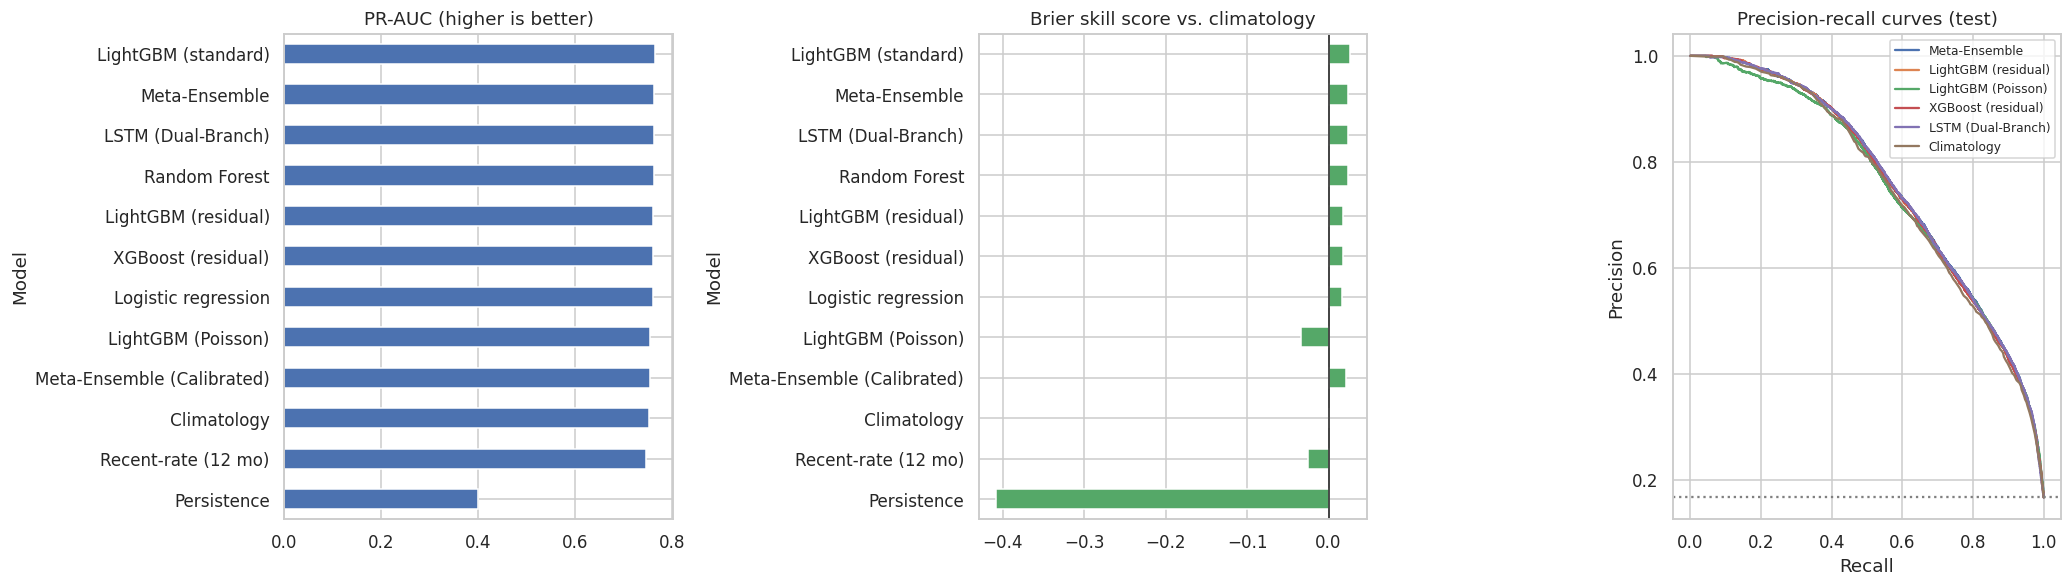

In [16]:
results = summarize(MODELS, y_va, y_te)
TABLES["main_results"] = results
order = results.sort_values("PR_AUC", ascending=False).index
cols_show = ["PR_AUC", "ROC_AUC", "Brier", "Brier_skill", "LogLoss", "Precision", "Recall", "F1", "Accuracy", "Acc_opt", "Threshold"]
display(results.loc[order, cols_show].round(4))
print(f"Test positive rate {y_te.mean():.3f} -> 'always no event' accuracy = {1 - y_te.mean():.4f}")

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
results.loc[order, "PR_AUC"][::-1].plot(kind="barh", ax=ax[0], color="#4c72b0"); ax[0].set_title("PR-AUC (higher is better)")
results.loc[order, "Brier_skill"][::-1].plot(kind="barh", ax=ax[1], color="#55a868"); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Brier skill score vs. climatology")
for n in [m for m in ["Meta-Ensemble", "LightGBM (residual)", "LightGBM (Poisson)", "XGBoost (residual)", "LSTM (Dual-Branch)", "Climatology"] if m in MODELS]:
    P, R, _ = precision_recall_curve(y_te, MODELS[n][1]); ax[2].plot(R, P, label=n, lw=1.5)
ax[2].axhline(y_te.mean(), color="gray", ls=":"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
ax[2].set_title("Precision-recall curves (test)"); ax[2].legend(fontsize=8)
show("03_main_results")

In [17]:
months = D["tmonth"][te]
uniq = np.unique(months); idx_by = {m: np.where(months == m)[0] for m in uniq}
rng = np.random.default_rng(SEED)
names = list(MODELS.keys())
boot = {n: [] for n in names}
for _ in range(N_BOOT):
    sel = rng.choice(uniq, len(uniq), replace=True)
    idx = np.concatenate([idx_by[m] for m in sel])
    for n in names:
        boot[n].append(average_precision_score(y_te[idx], MODELS[n][1][idx]))
ci_rows = [{"Model": n, "PR_AUC": average_precision_score(y_te, MODELS[n][1]),
            "CI_low": np.percentile(boot[n], 2.5), "CI_high": np.percentile(boot[n], 97.5)} for n in names]
ci_tab = pd.DataFrame(ci_rows).set_index("Model").sort_values("PR_AUC", ascending=False)
TABLES["bootstrap_ci"] = ci_tab; display(ci_tab.round(4))

base_name = max(["Climatology", "Persistence", "Recent-rate (12 mo)"], key=lambda n: average_precision_score(y_te, MODELS[n][1]))
for n in [m for m in ["Meta-Ensemble", "LightGBM (residual)", "LightGBM (Poisson)", "XGBoost (residual)", "LSTM (Dual-Branch)"] if m in MODELS]:
    d = np.array(boot[n]) - np.array(boot[base_name])
    lo, hi = np.percentile(d, [2.5, 97.5])
    verdict = "significantly better" if lo > 0 else ("significantly worse" if hi < 0 else "NOT significantly different")
    print(f"{n:22s} minus {base_name}: dPR-AUC = {d.mean():+.4f}  (95% CI {lo:+.4f} .. {hi:+.4f}) -> {verdict}")

,PR_AUC,CI_low,CI_high
Model,,,
LightGBM (standard),0.7633,0.7581,0.7684
Meta-Ensemble,0.7630,0.7578,0.7678
LSTM (Dual-Branch),0.7628,0.7576,0.7675
Random Forest,0.7626,0.7573,0.7678
LightGBM (residual),0.7609,0.7554,0.7659
XGBoost (residual),0.7607,0.7551,0.7659
Logistic regression,0.7594,0.7542,0.7639
LightGBM (Poisson),0.7543,0.7484,0.7594
Meta-Ensemble (Calibrated),0.7535,0.7483,0.7584


Meta-Ensemble          minus Climatology: dPR-AUC = +0.0119  (95% CI +0.0104 .. +0.0133) -> significantly better
LightGBM (residual)    minus Climatology: dPR-AUC = +0.0097  (95% CI +0.0084 .. +0.0110) -> significantly better
LightGBM (Poisson)     minus Climatology: dPR-AUC = +0.0031  (95% CI +0.0006 .. +0.0057) -> significantly better
XGBoost (residual)     minus Climatology: dPR-AUC = +0.0096  (95% CI +0.0082 .. +0.0109) -> significantly better
LSTM (Dual-Branch)     minus Climatology: dPR-AUC = +0.0116  (95% CI +0.0100 .. +0.0133) -> significantly better


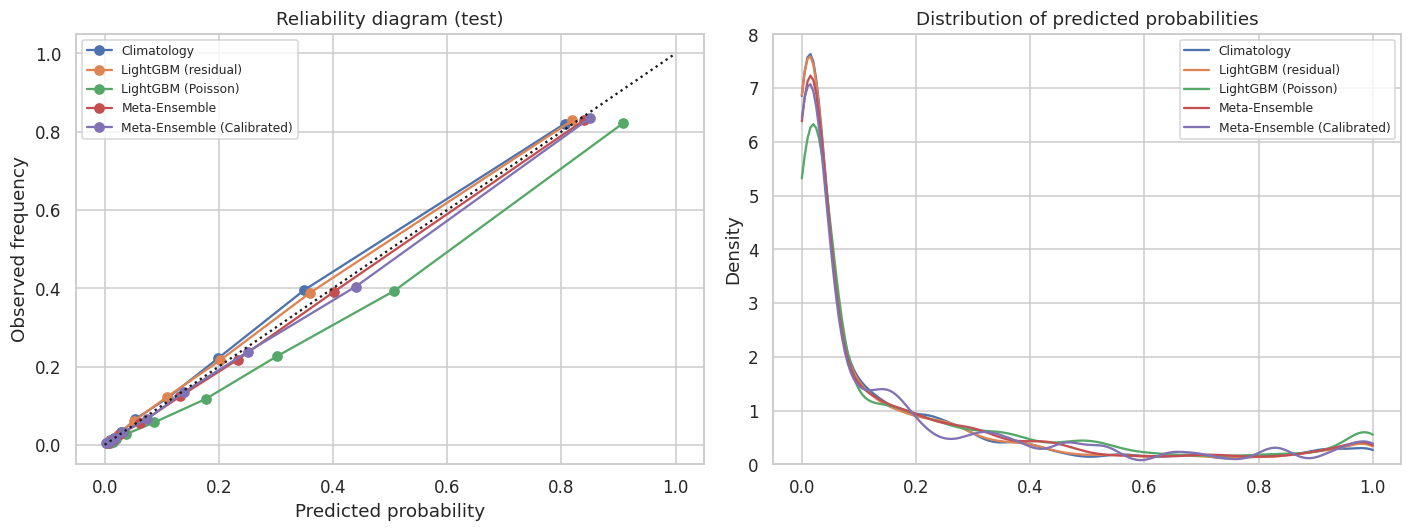

In [18]:
sel_models = [m for m in ["Climatology", "LightGBM (residual)", "LightGBM (Poisson)", "Meta-Ensemble", "Meta-Ensemble (Calibrated)"] if m in MODELS]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in sel_models:
    fr, mp = calibration_curve(y_te, np.clip(MODELS[n][1], 0, 1), n_bins=10, strategy="quantile")
    ax[0].plot(mp, fr, "o-", label=n)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("Predicted probability"); ax[0].set_ylabel("Observed frequency")
ax[0].set_title("Reliability diagram (test)"); ax[0].legend(fontsize=8)
for n in sel_models:
    sns.kdeplot(MODELS[n][1], ax=ax[1], label=n, clip=(0, 1))
ax[1].set_title("Distribution of predicted probabilities"); ax[1].legend(fontsize=8)
show("04_calibration")

## 10. Rolling-origin (walk-forward) validation (2016–2025)
Evaluates the upgraded **Residual LightGBM + Poisson LightGBM** blend across every year from 2016 to 2025.

,pos_rate,PRAUC_Upgraded,PRAUC_Climatology,PRAUC_Persistence,PRAUC_Recent,ROC_Upgraded,BSS_Upgraded,BSS_Recent
Year,,,,,,,,
2016,0.1618,0.7482,0.7376,0.3794,0.7341,0.9155,0.0114,-0.0221
2017,0.1620,0.7636,0.7551,0.3920,0.7460,0.9229,0.0087,-0.0377
2018,0.1717,0.7705,0.7584,0.4123,0.7526,0.9233,0.0301,-0.0187
2019,0.1716,0.7767,0.7644,0.4189,0.7553,0.9221,0.0280,-0.0305
2020,0.1766,0.7673,0.7567,0.4222,0.7515,0.9203,0.0319,-0.0122
2021,0.1721,0.7702,0.7591,0.4091,0.7505,0.9205,0.0261,-0.0263
2022,0.1695,0.7679,0.7608,0.3987,0.7504,0.9206,0.0116,-0.0342
2023,0.1662,0.7560,0.7495,0.3989,0.7430,0.9202,0.0030,-0.0304
2024,0.1614,0.7644,0.7570,0.3995,0.7467,0.9238,0.0012,-0.0409


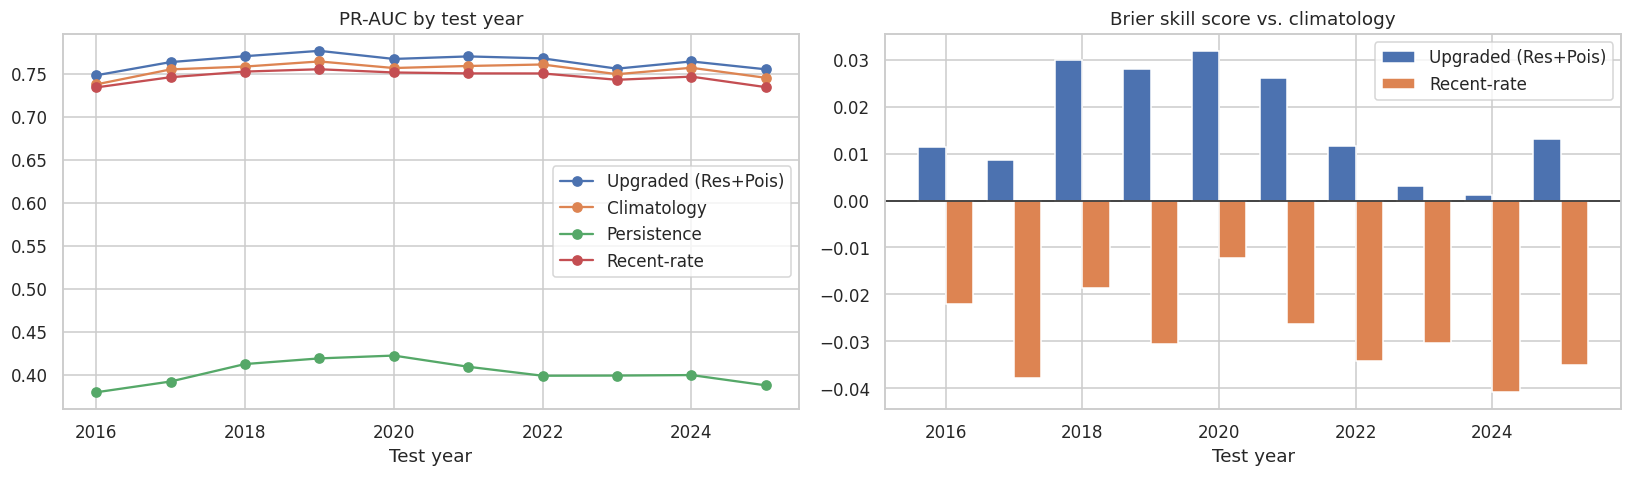

Upgraded PR-AUC over 10 test years: 0.7640 +- 0.0086
Upgraded Mean BSS: +0.0165 | Beats best baseline in 10/10 years


In [19]:
if RUN_ROLLING:
    rows = []
    for Y in range(ROLL_START_YEAR, END_YEAR + 1):
        trm, vam, tem = D["ty"] <= Y - 2, D["ty"] == Y - 1, D["ty"] == Y
        ytr, yva, yte = y_all[trm], y_all[vam], y_all[tem]
        if yte.sum() == 0 or yva.sum() == 0:
            continue
        p_c_all = p_climatology(D, y_all, trm, smooth_prior=0.0)
        p_c_sm = np.clip(p_climatology(D, y_all, trm, smooth_prior=2.0), 1e-4, 1 - 1e-4)
        init_y = logit(p_c_sm)

        m_res, rcols = fit_lgbm_residual(X[trm], ytr, init_y[trm], X[vam], yva, init_y[vam])
        p_res = predict_lgbm_residual(m_res, rcols, X[tem], init_y[tem])

        m_pois = fit_lgbm_poisson(X[trm], y_cnt_all[trm], X[vam], y_cnt_all[vam])
        p_pois = poisson_prob(m_pois, X[tem])

        p_blend = 0.6 * p_res + 0.4 * p_pois
        p_c = p_c_all[tem]
        p_p = p_persistence(D, y_all, trm, TARGET_MAG)[tem]
        p_r = p_recent(D, y_all, trm, TARGET_MAG)[tem]
        bc = brier_score_loss(yte, p_c)

        rows.append({
            "Year": Y, "pos_rate": yte.mean(),
            "PRAUC_Upgraded": average_precision_score(yte, p_blend),
            "PRAUC_Climatology": average_precision_score(yte, p_c),
            "PRAUC_Persistence": average_precision_score(yte, p_p),
            "PRAUC_Recent": average_precision_score(yte, p_r),
            "ROC_Upgraded": roc_auc_score(yte, p_blend),
            "BSS_Upgraded": 1 - brier_score_loss(yte, p_blend) / bc,
            "BSS_Recent": 1 - brier_score_loss(yte, p_r) / bc
        })
    roll = pd.DataFrame(rows).set_index("Year"); TABLES["rolling_origin"] = roll
    display(roll.round(4))

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for c, lab in [("PRAUC_Upgraded", "Upgraded (Res+Pois)"), ("PRAUC_Climatology", "Climatology"),
                   ("PRAUC_Persistence", "Persistence"), ("PRAUC_Recent", "Recent-rate")]:
        ax[0].plot(roll.index, roll[c], "o-", label=lab)
    ax[0].set_title("PR-AUC by test year"); ax[0].legend(); ax[0].set_xlabel("Test year")
    ax[1].bar(roll.index - 0.2, roll["BSS_Upgraded"], 0.4, label="Upgraded (Res+Pois)")
    ax[1].bar(roll.index + 0.2, roll["BSS_Recent"], 0.4, label="Recent-rate")
    ax[1].axhline(0, color="k", lw=1); ax[1].set_title("Brier skill score vs. climatology"); ax[1].legend(); ax[1].set_xlabel("Test year")
    show("05_rolling_origin")
    best_base = roll[["PRAUC_Climatology", "PRAUC_Persistence", "PRAUC_Recent"]].max(axis=1)
    print(f"Upgraded PR-AUC over {len(roll)} test years: {roll.PRAUC_Upgraded.mean():.4f} +- {roll.PRAUC_Upgraded.std():.4f}")
    print(f"Upgraded Mean BSS: {roll.BSS_Upgraded.mean():+.4f} | Beats best baseline in {(roll.PRAUC_Upgraded > best_base).sum()}/{len(roll)} years")
else:
    print("RUN_ROLLING = False")

## 11. What drives the forecast? Ablation and feature importance
Because **Residual LightGBM** starts from climatology log-odds, its feature importances reveal which *dynamic* signals (ETAS decay, anomalies, neighbor rings) actually drive skill beyond static geography.

,n_features,PR_AUC,ROC_AUC,Brier_skill,dPR_AUC_vs_all
Setting,,,,,
All features (Residual LGB),42,0.7609,0.9184,0.0173,0.0000
without current month,37,0.7608,0.9184,0.0170,-0.0001
without rolling history,33,0.7605,0.9183,0.0167,-0.0004
without ETAS / Omori decay,36,0.7605,0.9183,0.0169,-0.0003
without anomalies & ratios,37,0.7605,0.9182,0.0169,-0.0003
without recency,39,0.7609,0.9184,0.0174,0.0001
without neighbours,36,0.7606,0.9181,0.0168,-0.0002
without long-term rate / b-value,38,0.7604,0.9181,0.0158,-0.0005
without location & area,38,0.7609,0.9184,0.0172,0.0000


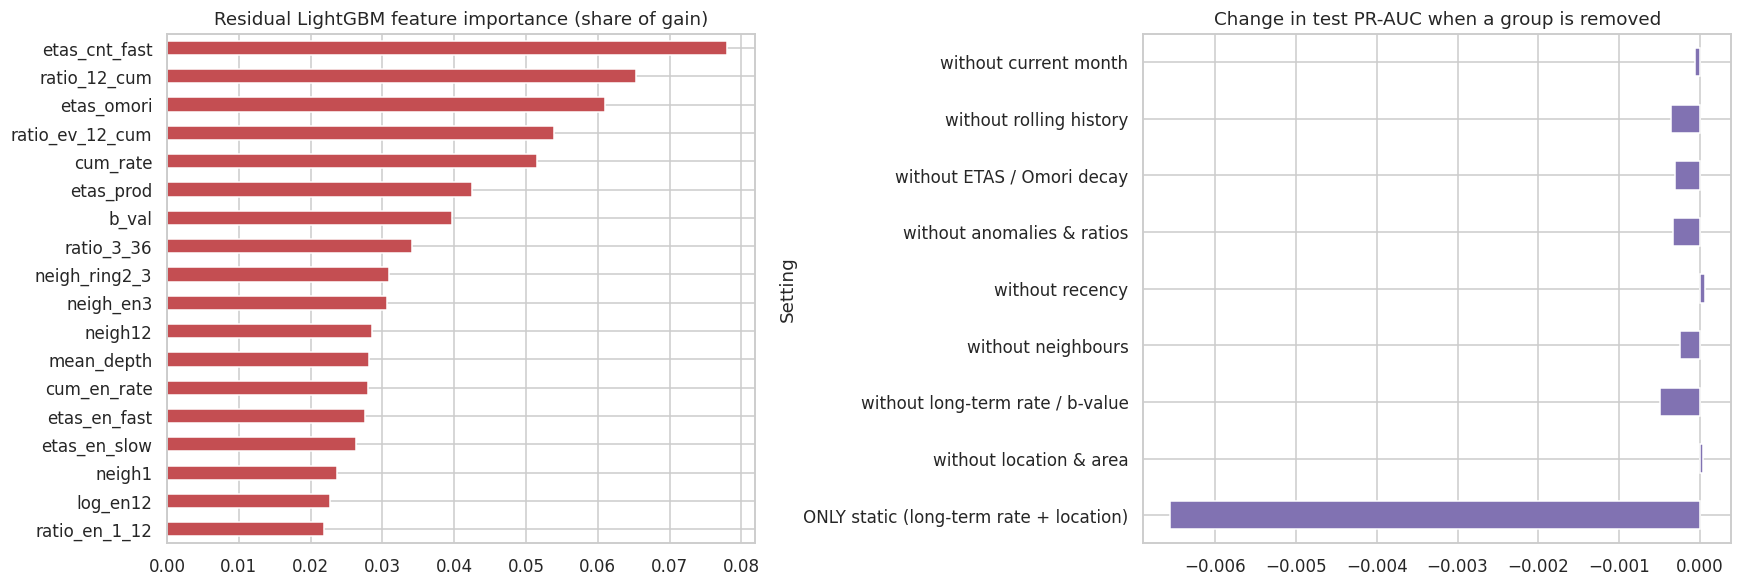

In [20]:
b_clim = brier_score_loss(y_te, MODELS["Climatology"][1])
abl = []
def run_cols_res(cols, label):
    m, rcols = fit_lgbm_residual(X[tr], y_tr, init_all[tr], X[va], y_va, init_all[va], cols=cols)
    p = predict_lgbm_residual(m, rcols, X[te], init_all[te])
    abl.append({"Setting": label, "n_features": len(cols), "PR_AUC": average_precision_score(y_te, p),
                "ROC_AUC": roc_auc_score(y_te, p), "Brier_skill": 1 - brier_score_loss(y_te, p) / b_clim})

if RUN_ABLATION:
    run_cols_res(FEATURES, "All features (Residual LGB)")
    for g, cols in FEATURE_GROUPS.items():
        run_cols_res([f for f in FEATURES if f not in cols], f"without {g}")
    run_cols_res(FEATURE_GROUPS["long-term rate / b-value"] + FEATURE_GROUPS["location & area"], "ONLY static (long-term rate + location)")
    abl_tab = pd.DataFrame(abl).set_index("Setting")
    abl_tab["dPR_AUC_vs_all"] = abl_tab["PR_AUC"] - abl_tab.loc["All features (Residual LGB)", "PR_AUC"]
    TABLES["ablation"] = abl_tab; display(abl_tab.round(4))

imp = pd.Series(lgbm_res.feature_importance(importance_type="gain"), index=res_cols).sort_values(ascending=False)
imp = imp / max(imp.sum(), 1e-12)
fig, ax = plt.subplots(1, 2 if RUN_ABLATION else 1, figsize=(16 if RUN_ABLATION else 8, 5.5)); ax = np.atleast_1d(ax)
imp.head(18)[::-1].plot(kind="barh", ax=ax[0], color="#c44e52")
ax[0].set_title("Residual LightGBM feature importance (share of gain)")
if RUN_ABLATION:
    abl_tab["dPR_AUC_vs_all"].iloc[1:][::-1].plot(kind="barh", ax=ax[1], color="#8172b2")
    ax[1].set_title("Change in test PR-AUC when a group is removed")
show("06_importance_ablation")

## 12. Regional performance (Meta-Ensemble vs. Climatology)

,cells,pos_rate,PR_AUC_Ensemble,PR_AUC_Climatology,Brier_skill_vs_clim
Region,,,,,
Japan - Kuril,28,0.4196,0.9266,0.9112,0.0262
Indonesia - SE Asia,41,0.4858,0.9462,0.9433,0.0295
India - Himalaya - Hindu Kush,39,0.2603,0.6843,0.6553,0.0176
Middle East - Mediterranean,45,0.1837,0.5363,0.4817,0.0322
Western South America,45,0.3889,0.8253,0.8171,0.0244
Central America - Mexico,36,0.2204,0.8056,0.7863,0.0171
Alaska - Aleutians,33,0.1515,0.5908,0.5638,0.0279
Tonga - Fiji - Kermadec - NZ,21,0.4333,0.9105,0.8930,-0.0016


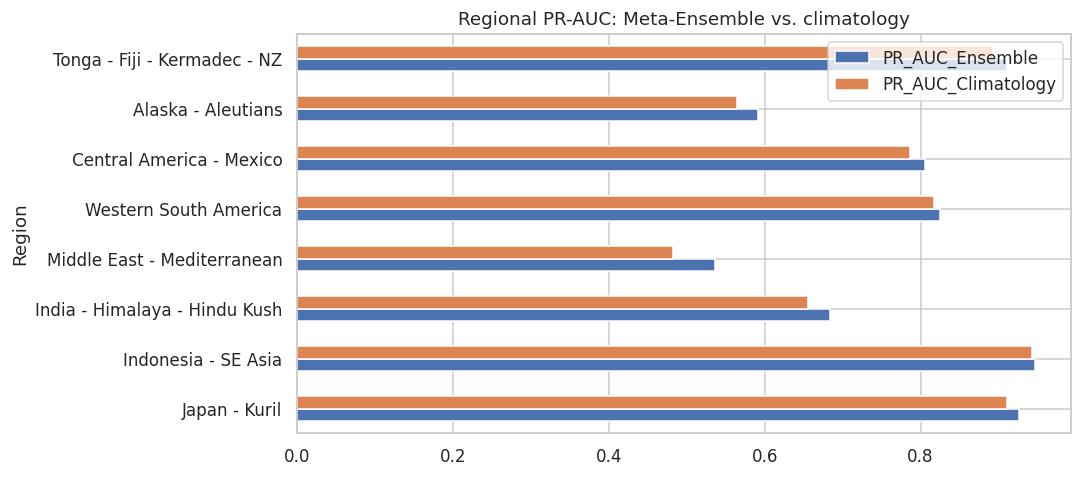

In [21]:
REGIONS = {
    "Japan - Kuril":            (25, 52, 125, 165),
    "Indonesia - SE Asia":      (-12, 10, 90, 145),
    "India - Himalaya - Hindu Kush": (5, 40, 65, 100),
    "Middle East - Mediterranean":   (25, 46, -10, 62),
    "Western South America":    (-50, 12, -85, -62),
    "Central America - Mexico": (5, 33, -120, -75),
    "Alaska - Aleutians":       (50, 72, -180, -130),
    "Tonga - Fiji - Kermadec - NZ": (-50, -10, 165, 180),
}
lat_s, lon_s = D["lat_c"][D["ci"]][te], D["lon_c"][D["ci"]][te]
p_best, p_c = MODELS["Meta-Ensemble"][1], MODELS["Climatology"][1]
rows = []
for name, (a, b_, c, d) in REGIONS.items():
    mk = (lat_s >= a) & (lat_s <= b_) & (lon_s >= c) & (lon_s <= d)
    if mk.sum() < 500 or y_te[mk].sum() < 10 or y_te[mk].sum() == mk.sum():
        continue
    rows.append({
        "Region": name, "cells": len(np.unique(D["ci"][te][mk])), "pos_rate": y_te[mk].mean(),
        "PR_AUC_Ensemble": average_precision_score(y_te[mk], p_best[mk]),
        "PR_AUC_Climatology": average_precision_score(y_te[mk], p_c[mk]),
        "Brier_skill_vs_clim": 1 - brier_score_loss(y_te[mk], p_best[mk]) / brier_score_loss(y_te[mk], p_c[mk])
    })
reg = pd.DataFrame(rows).set_index("Region"); TABLES["regional"] = reg; display(reg.round(4))
if len(reg):
    ax = reg[["PR_AUC_Ensemble", "PR_AUC_Climatology"]].plot(kind="barh", figsize=(10, 4.5))
    ax.set_title("Regional PR-AUC: Meta-Ensemble vs. climatology")
    show("07_regional")

## 13. Sensitivity analysis
### 13a. Target magnitude

In [22]:
if RUN_SENSITIVITY:
    rows = []
    for thr in SENS_TARGETS:
        y = targets(D, thr)
        if y[tr].sum() < 100 or y[va].sum() < 10 or y[te].sum() < 10:
            print(f"M >= {thr}: too few positive samples, skipped"); continue
        pc_all = p_climatology(D, y, tr, smooth_prior=0.0)
        pc_sm = np.clip(p_climatology(D, y, tr, smooth_prior=2.0), 1e-4, 1 - 1e-4)
        init_thr = logit(pc_sm)
        m, rcols = fit_lgbm_residual(X[tr], y[tr], init_thr[tr], X[va], y[va], init_thr[va])
        pl = predict_lgbm_residual(m, rcols, X[te], init_thr[te])
        pc, pr_ = pc_all[te], p_recent(D, y, tr, thr)[te]
        bc = brier_score_loss(y[te], pc)
        rows.append({"Target": f"M >= {thr}", "pos_rate_test": y[te].mean(),
                     "PR_AUC_ResLGB": average_precision_score(y[te], pl),
                     "PR_AUC_Climatology": average_precision_score(y[te], pc),
                     "PR_AUC_Recent": average_precision_score(y[te], pr_),
                     "ROC_ResLGB": roc_auc_score(y[te], pl),
                     "BSS_ResLGB": 1 - brier_score_loss(y[te], pl) / bc})
    sens_t = pd.DataFrame(rows).set_index("Target"); TABLES["sensitivity_target_magnitude"] = sens_t; display(sens_t.round(4))

,pos_rate_test,PR_AUC_ResLGB,PR_AUC_Climatology,PR_AUC_Recent,ROC_ResLGB,BSS_ResLGB
Target,,,,,,
M >= 4.5,0.1674,0.7609,0.7511,0.7448,0.9184,0.0173
M >= 5.0,0.0712,0.5422,0.5258,0.5098,0.9116,0.0115
M >= 5.5,0.0261,0.2695,0.2538,0.2303,0.9081,0.0078
M >= 6.0,0.0086,0.1014,0.0922,0.0828,0.9094,0.0043


### 13b. Grid resolution

In [29]:
if RUN_SENSITIVITY:
    rows = []
    for g in SENS_GRIDS:
        Dg = D if g == GRID_DEG else build_dataset(g)
        Xg = Dg["X"]; trg, vag, teg = split_masks(Dg, TRAIN_END_YEAR, VAL_END_YEAR); yg = targets(Dg, TARGET_MAG)
        pc_all = p_climatology(Dg, yg, trg, smooth_prior=0.0)
        pc_sm = np.clip(p_climatology(Dg, yg, trg, smooth_prior=2.0), 1e-4, 1 - 1e-4)
        init_g = logit(pc_sm)
        m, rcols = fit_lgbm_residual(Xg[trg], yg[trg], init_g[trg], Xg[vag], yg[vag], init_g[vag])
        pl = predict_lgbm_residual(m, rcols, Xg[teg], init_g[teg])
        pc = pc_all[teg]; bc = brier_score_loss(yg[teg], pc)
        rows.append({"Grid (deg)": g, "cells": Dg["C"], "pos_rate_test": yg[teg].mean(),
                     "PR_AUC_ResLGB": average_precision_score(yg[teg], pl),
                     "PR_AUC_Climatology": average_precision_score(yg[teg], pc),
                     "ROC_ResLGB": roc_auc_score(yg[teg], pl),
                     "BSS_ResLGB": 1 - brier_score_loss(yg[teg], pl) / bc})
        if g != GRID_DEG:
            del Dg, Xg
    sens_g = pd.DataFrame(rows).set_index("Grid (deg)"); TABLES["sensitivity_grid"] = sens_g; display(sens_g.round(4))

,cells,pos_rate_test,PR_AUC_ResLGB,PR_AUC_Climatology,ROC_ResLGB,BSS_ResLGB
Grid (deg),,,,,,
10.0,417,0.2657,0.8474,0.8407,0.9242,0.0177
5.0,1036,0.1674,0.7609,0.7511,0.9184,0.0173
3.0,1858,0.1243,0.6794,0.6662,0.9091,0.0170


## 14. Conditional magnitude: how large will the biggest event be?

In [30]:
pos_tr, pos_va, pos_te = tr & (D["ymax"] > 0), va & (D["ymax"] > 0), te & (D["ymax"] > 0)
ytr_m, yva_m, yte_m = D["ymax"][pos_tr], D["ymax"][pos_va], D["ymax"][pos_te]

glob_mean = ytr_m.mean()
cell_mean = (np.bincount(D["ci"][pos_tr], weights=ytr_m, minlength=D["C"]) / np.maximum(np.bincount(D["ci"][pos_tr], minlength=D["C"]), 1))
cell_mean = np.where(np.bincount(D["ci"][pos_tr], minlength=D["C"]) > 0, cell_mean, glob_mean)

reg_m = lgb.LGBMRegressor(**LGB_PARAMS, objective="regression_l1")
reg_m.fit(X[pos_tr], ytr_m, eval_set=[(X[pos_va], yva_m)], eval_metric="l1",
          callbacks=[lgb.early_stopping(60, verbose=False), lgb.log_evaluation(0)])
preds = {"Predict train mean": np.full(pos_te.sum(), glob_mean), "Predict cell mean": cell_mean[D["ci"][pos_te]],
         "LightGBM regressor": reg_m.predict(X[pos_te])}
mag_tab = pd.DataFrame({n: {"MAE": mean_absolute_error(yte_m, p), "RMSE": np.sqrt(mean_squared_error(yte_m, p)), "R2": r2_score(yte_m, p)}
                        for n, p in preds.items()}).T
TABLES["conditional_magnitude"] = mag_tab; display(mag_tab.round(4))

,MAE,RMSE,R2
Predict train mean,0.3826,0.4961,-0.0065
Predict cell mean,0.3539,0.4691,0.1004
LightGBM regressor,0.3282,0.4730,0.0853


## 15. Seismic hazard proxy from the Gutenberg–Richter law

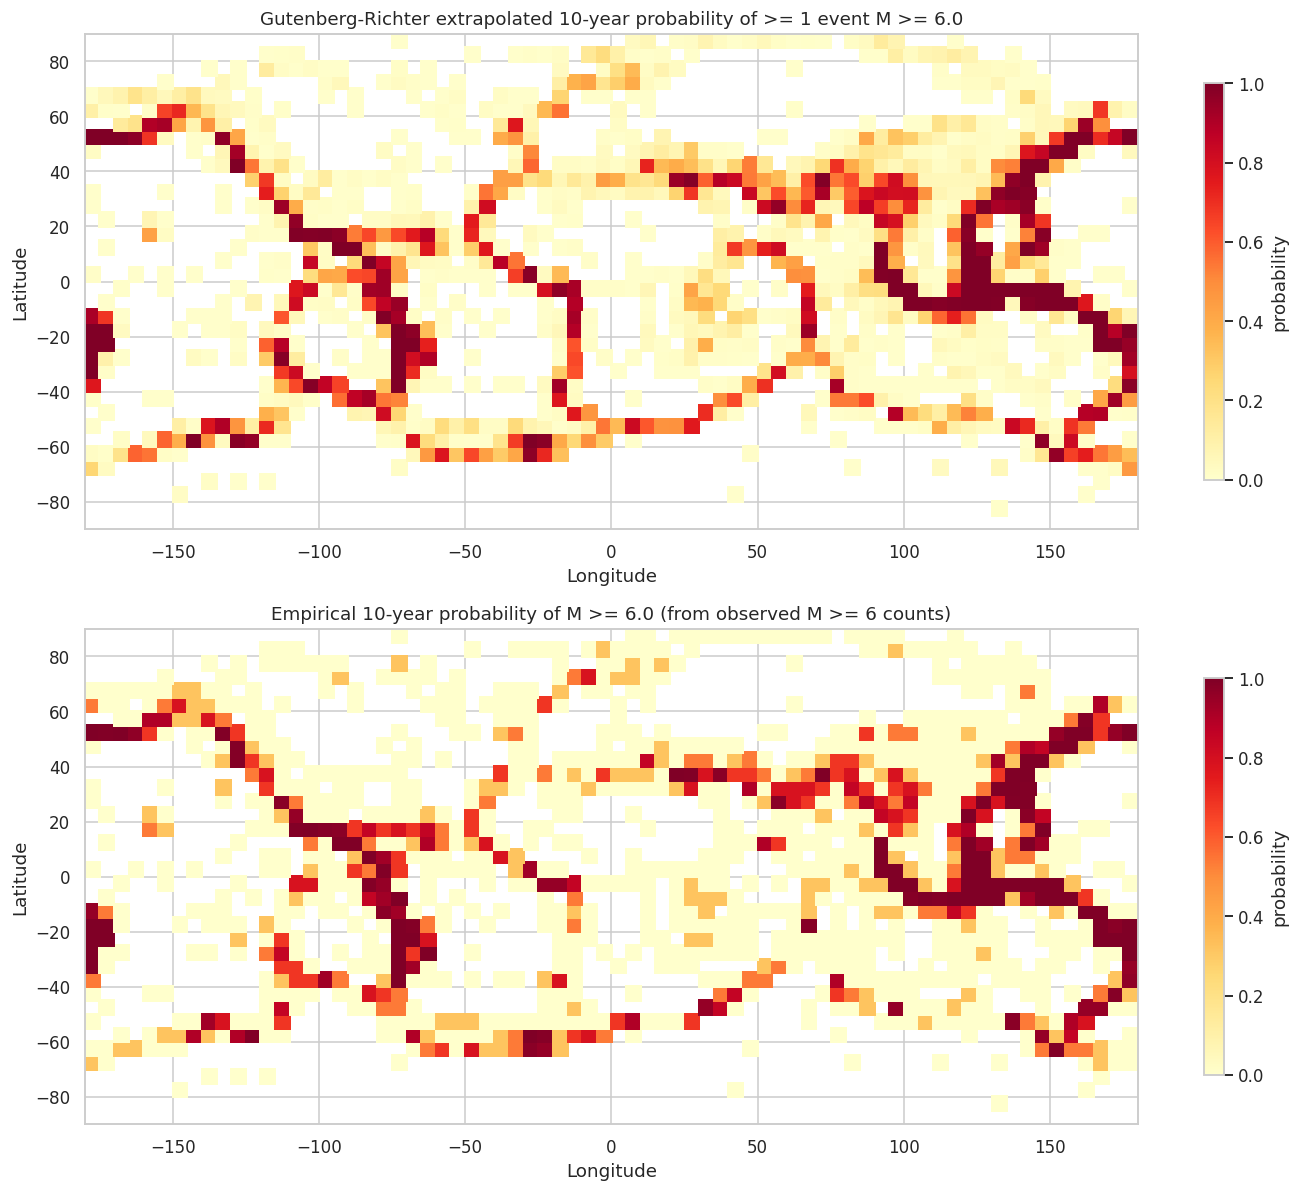

Spearman rank agreement: rho = 0.781


,lat,lon,n,b_shrunk,P10_M6_GR,P10_M6_obs
879,37.5,142.5,6158,1.198,1.0,1.0
480,-7.5,152.5,4261,1.101,1.0,1.0
440,-12.5,167.5,3503,1.058,1.0,1.0
392,-17.5,167.5,2979,1.033,1.0,1.0
354,-17.5,-172.5,3946,1.136,1.0,1.0
66,-57.5,-27.5,3751,1.128,1.0,1.0
267,-27.5,-177.5,3341,1.099,1.0,1.0
575,2.5,127.5,5004,1.244,1.0,1.0
233,-32.5,-177.5,4239,1.235,1.0,1.0
351,-22.5,172.5,1842,0.998,1.0,1.0


In [31]:
from scipy.stats import spearmanr
G = GRID_DEG; n_lon = D["n_lon"]
lat_b = np.clip(((df["latitude"].values + 90) // G).astype(int), 0, D["n_lat"] - 1)
lon_b = np.clip(((df["longitude"].values + 180) // G).astype(int), 0, n_lon - 1)
ev_tab = pd.DataFrame({"cell": lat_b * n_lon + lon_b, "mag": df["mag"].values, "m6": (df["mag"].values >= 6).astype(int)})
cs = ev_tab.groupby("cell").agg(n=("mag", "size"), mean_mag=("mag", "mean"), max_mag=("mag", "max"), n6=("m6", "sum")).reset_index()
cs["lat"] = (cs["cell"] // n_lon) * G - 90 + G / 2; cs["lon"] = (cs["cell"] % n_lon) * G - 180 + G / 2
years = END_YEAR - START_YEAR + 1
b_cell = np.log10(np.e) / (cs["mean_mag"] - (MIN_MAG - 0.05)); K = 50
cs["b_shrunk"] = (cs["n"] * b_cell + K * b_global) / (cs["n"] + K)
cs["rate_45"] = cs["n"] / years
cs["P10_M6_GR"] = 1 - np.exp(-10 * cs["rate_45"] * 10 ** (-cs["b_shrunk"] * (6.0 - MIN_MAG)))
cs["P10_M6_obs"] = 1 - np.exp(-10 * cs["n6"] / years)
rho = float(spearmanr(cs["P10_M6_GR"], cs["P10_M6_obs"])[0])
TABLES["hazard_proxy_by_cell"] = cs

def cell_map(ax, vals, title, cmap, label, vmin=None, vmax=None):
    sc = ax.scatter(cs["lon"], cs["lat"], c=vals, s=(G * 2.2) ** 2, marker="s", cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0)
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_title(title); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    plt.colorbar(sc, ax=ax, label=label, shrink=0.8)

fig, ax = plt.subplots(2, 1, figsize=(13, 11))
cell_map(ax[0], cs["P10_M6_GR"], "Gutenberg-Richter extrapolated 10-year probability of >= 1 event M >= 6.0", "YlOrRd", "probability", 0, 1)
cell_map(ax[1], cs["P10_M6_obs"], "Empirical 10-year probability of M >= 6.0 (from observed M >= 6 counts)", "YlOrRd", "probability", 0, 1)
show("08_hazard_proxy")
print(f"Spearman rank agreement: rho = {rho:.3f}")
display(cs.sort_values("P10_M6_GR", ascending=False).head(10)[["lat", "lon", "n", "b_shrunk", "P10_M6_GR", "P10_M6_obs"]].round(3))

## 16. Next-month forecast map (experimental)
Retrains the **Residual LightGBM + Poisson LightGBM** models on all labelled data and produces a blended probability forecast for the next calendar month.

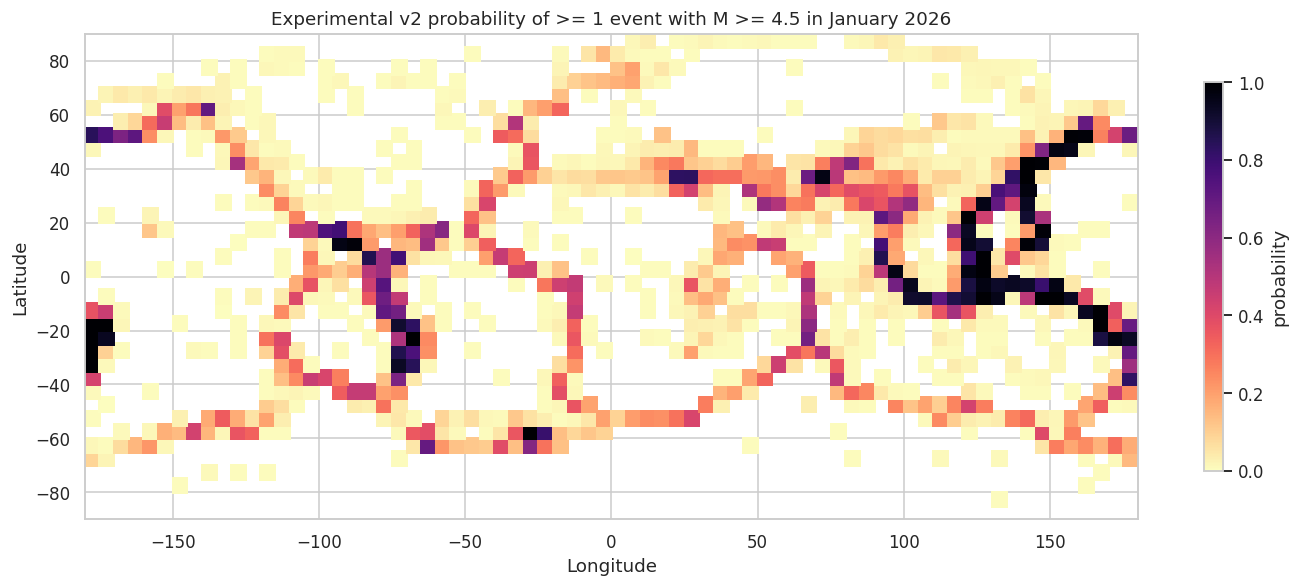

,lat,lon,prob_next_month,prob_residual_lgb,prob_poisson_lgb,events_last_12_months,etas_omori_score,long_term_active_month_share
524,7.5,127.5,1.000,1.000,1.000,216.0,3.795,1.000
259,-22.5,-177.5,1.000,0.999,1.000,153.0,3.291,1.000
490,2.5,127.5,1.000,0.999,1.000,162.0,3.319,1.000
295,-17.5,-177.5,1.000,0.999,1.000,96.0,3.033,1.000
60,-57.5,-27.5,0.999,0.999,1.000,151.0,3.442,1.000
373,-12.5,167.5,0.999,0.999,1.000,107.0,3.162,1.000
296,-17.5,-172.5,0.999,0.999,1.000,118.0,3.048,1.000
200,-32.5,-177.5,0.999,0.999,1.000,119.0,2.867,0.997
411,-7.5,152.5,0.999,0.999,1.000,264.0,3.338,0.997
224,-27.5,-177.5,0.999,0.998,1.000,101.0,3.427,0.994


In [32]:
T, C = D["T"], D["C"]
all_mask = np.ones(len(y_all), dtype=bool)
clim_full = np.clip(p_climatology(D, y_all, all_mask, smooth_prior=2.0), 1e-4, 1 - 1e-4)
init_full = logit(clim_full)

# Retrain Residual LightGBM on all data
bi_res = max(50, int((lgbm_res.best_iteration or 300) * 1.15))
d_full = lgb.Dataset(X[FEATURES], label=y_all, init_score=init_full)
lgb_core = {k: v for k, v in LGB_PARAMS.items() if k not in ("n_estimators", "importance_type", "n_jobs", "verbose")}
lgb_core.update({"objective": "binary", "num_leaves": 23, "min_child_samples": 150, "reg_lambda": 15.0, "nthread": -1, "verbosity": -1})
final_res = lgb.train(lgb_core, d_full, num_boost_round=bi_res)

# Retrain Poisson LightGBM on all data
bi_pois = max(50, int((lgbm_pois.best_iteration_ or 300) * 1.15))
final_pois = lgb.LGBMRegressor(**{**LGB_PARAMS, "objective": "poisson", "n_estimators": bi_pois}).fit(X[FEATURES], y_cnt_all)

ci_n, ti_n = np.arange(C), np.full(C, T - 1)
X_next = pd.DataFrame({k: D["FA"][k][ci_n, ti_n] for k in FEATURES})
# Cell-level climatology for next month
num_c = np.bincount(D["ci"], weights=y_all, minlength=C)
den_c = np.bincount(D["ci"], minlength=C)
clim_next = np.clip((num_c + 2.0 * y_all.mean()) / (den_c + 2.0), 1e-4, 1 - 1e-4)

p_next_res = expit(logit(clim_next) + final_res.predict(X_next[FEATURES], raw_score=True))
p_next_pois = 1.0 - np.exp(-np.clip(final_pois.predict(X_next[FEATURES]), 0.0, 50.0))
p_next_blend = 0.6 * p_next_res + 0.4 * p_next_pois

fc = pd.DataFrame({
    "lat": D["lat_c"], "lon": D["lon_c"],
    "prob_next_month": p_next_blend,
    "prob_residual_lgb": p_next_res,
    "prob_poisson_lgb": p_next_pois,
    "events_last_12_months": X_next["r12"].values,
    "etas_omori_score": X_next["etas_omori"].values,
    "long_term_active_month_share": X_next["cum_rate"].values,
})
FORECAST_MONTH = pd.Timestamp(f"{END_YEAR + 1}-01-01").strftime("%B %Y")
TABLES["forecast_next_month"] = fc

fig, ax = plt.subplots(figsize=(13, 5.5))
sc = ax.scatter(fc["lon"], fc["lat"], c=fc["prob_next_month"], s=(G * 2.2) ** 2, marker="s", cmap="magma_r", vmin=0, vmax=1, linewidths=0)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"Experimental v2 probability of >= 1 event with M >= {TARGET_MAG} in {FORECAST_MONTH}")
plt.colorbar(sc, ax=ax, label="probability", shrink=0.8)
show("09_forecast_map")
display(fc.sort_values("prob_next_month", ascending=False).head(15).round(3))

In [33]:
if "RUN_DEMO" not in globals():
    RUN_DEMO = False

if RUN_DEMO:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"])
    import gradio as gr

    def lookup(lat, lon):
        dlon = (fc["lon"] - lon + 180) % 360 - 180
        d = (fc["lat"] - lat).abs() + dlon.abs()
        i = d.idxmin(); r = fc.loc[i]
        if d[i] > G:
            return "No modelled cell here (the cell had no recorded events before %d)." % ROLL_START_YEAR
        return (f"Cell centred at ({r.lat:.1f}, {r.lon:.1f})\nProbability of >=1 event with M >= {TARGET_MAG} in {FORECAST_MONTH}: "
                f"{100 * r.prob_next_month:.1f}%\nEvents in the last 12 months: {int(r.events_last_12_months)}")

    gr.Interface(fn=lookup, inputs=[gr.Number(label="Latitude", value=35.0), gr.Number(label="Longitude", value=139.0)],
                 outputs=gr.Textbox(label="Forecast"), title="Experimental monthly earthquake probability (v2)",
                 description="Research prototype. Not an early-warning system.").launch(share=True)

## 17. Save all tables, figures and models

In [34]:
import json, zipfile
from pathlib import Path

OUT_DIR = Path("/content/outputs_v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save all result tables
if "TABLES" not in globals():
    TABLES = {}

print(f"Tables in memory ({len(TABLES)}):", list(TABLES.keys()))
if len(TABLES) == 0:
    print("WARNING: TABLES is empty! Make sure you ran Sections 9–16 before this cell.")
for k, v in TABLES.items():
    p = OUT_DIR / f"{k}.csv"
    v.to_csv(p)
    print(f"  Saved {p.name} ({p.stat().st_size / 1024:.1f} KB)")

# 2. Save cleaned catalog
if "df" in globals():
    p = OUT_DIR / "usgs_clean_catalog.csv.gz"
    df.drop(columns=["mag_family"], errors="ignore").to_csv(p, index=False, compression="gzip")
    print(f"  Saved {p.name} ({p.stat().st_size / 1024:.1f} KB)")

# 3. Save trained models (only if they exist in memory)
if "lgbm_res" in globals():
    lgbm_res.save_model(str(OUT_DIR / "lightgbm_residual_model.txt"))
if "lgbm_pois" in globals():
    lgbm_pois.booster_.save_model(str(OUT_DIR / "lightgbm_poisson_model.txt"))
if "xgb_model" in globals():
    xgb_model.save_model(str(OUT_DIR / "xgboost_residual_model.json"))
if globals().get("RUN_LSTM", False) and "LSTM_INFO" in globals() and "net" in LSTM_INFO:
    LSTM_INFO["net"].save(str(OUT_DIR / "lstm_dual_branch_last_seed.keras"))

# 4. Save config
cfg = {k: globals()[k] for k in ["START_YEAR", "END_YEAR", "MIN_MAG", "TARGET_MAG", "GRID_DEG", "LOOKBACK",
                                  "TRAIN_END_YEAR", "VAL_END_YEAR", "ROLL_START_YEAR", "N_SEEDS", "SEED"] if k in globals()}
if "FEATURES" in globals():
    cfg["features"] = FEATURES
if "ens_members" in globals() and "ENS_WEIGHTS" in globals():
    cfg["ensemble_members"] = ens_members
    cfg["ensemble_weights"] = [round(float(w), 4) for w in ENS_WEIGHTS]
(OUT_DIR / "config.json").write_text(json.dumps(cfg, indent=2))

# 5. Zip and verify every file inside
zip_path = "/content/earthquake_project_v2_outputs.zip"
files_to_zip = [p for p in OUT_DIR.rglob("*") if p.is_file()]
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in files_to_zip:
        z.write(p, arcname=str(p.relative_to(OUT_DIR)))

print(f"\nZIP created: {zip_path} | {len(files_to_zip)} files | {Path(zip_path).stat().st_size / (1024*1024):.2f} MB")
for p in sorted(files_to_zip):
    print("  -", p.relative_to(OUT_DIR))

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Tables in memory (12): ['cleaning_log', 'lstm_seeds', 'main_results', 'bootstrap_ci', 'rolling_origin', 'ablation', 'regional', 'sensitivity_target_magnitude', 'sensitivity_grid', 'conditional_magnitude', 'hazard_proxy_by_cell', 'forecast_next_month']
  Saved cleaning_log.csv (0.3 KB)
  Saved lstm_seeds.csv (0.2 KB)
  Saved main_results.csv (2.8 KB)
  Saved bootstrap_ci.csv (0.9 KB)
  Saved rolling_origin.csv (1.7 KB)
  Saved ablation.csv (1.1 KB)
  Saved regional.csv (0.9 KB)
  Saved sensitivity_target_magnitude.csv (0.6 KB)
  Saved sensitivity_grid.csv (0.4 KB)
  Saved conditional_magnitude.csv (0.2 KB)
  Saved hazard_proxy_by_cell.csv (126.0 KB)
  Saved forecast_next_month.csv (100.4 KB)
  Saved usgs_clean_catalog.csv.gz (8455.3 KB)

ZIP created: /content/earthquake_project_v2_outputs.zip | 27 files | 11.94 MB
  - ablation.csv
  - bootstrap_ci.csv
  - cleaning_log.csv
  - conditional_magnitude.csv
  - config.json
  - figures/01_eda_overview.png
  - figures/02_gutenberg_richter.png
 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>